# Project Name    - **Flipkart Customer Service Satisfaction**



# **Project Summary**

Flipkart’s growth depends on the quality of its customer support, and every support interaction ends with a Customer Satisfaction (CSAT) survey score from 1 to 5. This project uses the support interaction data to understand what drives customer satisfaction and to predict the CSAT score of an interaction.

The dataset has 85,907 support interactions and 20 columns. It covers the support channel, issue category and sub-category, order and product details, timestamps for when the issue was reported and responded to, and agent details such as agent name, supervisor, manager, tenure bucket and shift. The target variable is CSAT Score.

The target is heavily imbalanced: about 69% of customers gave a score of 5, 13% gave 4, 13% gave 1, 3% gave 3 and only 1.5% gave 2. Several columns are also largely empty. Connected handling time is about 99.7% missing, and order date, customer city, product category and item price are about 80% missing. Customer remarks are about 67% missing.

The goal is to find the factors behind low satisfaction, understand how channels, issue categories and agent teams perform, and build a model that predicts the CSAT score. The best model, a tuned Gradient Boosting classifier, reaches about 65.8% accuracy and identifies dissatisfied customers (score 1) with an F1-score of 0.42.

# **GitHub Link -**

github.com/DanishMullaData

# **Problem Statement**


Flipkart handles a very large number of customer support interactions across channels such as inbound, outbound and email, covering issues like order problems, returns and product queries. After each interaction, customers rate their satisfaction with a CSAT score from 1 to 5. Low scores point to poor service, and they put customer loyalty, repeat purchases and brand reputation at risk.

Flipkart currently has no clear view of which factors drive these scores. It is not clear how support channel, issue category, response time, agent tenure, shift or product type affect satisfaction, or which teams and categories need the most improvement.

The objective of this project is to analyse the customer support data to:

Identify the key drivers of customer satisfaction.
Understand how performance differs across channels, issue categories, agents and shifts.
Predict the CSAT score (1 to 5) of a support interaction, so that Flipkart can act early on likely dissatisfied customers and improve service quality.

# ***Let's Begin !***

### Import Libraries

In [65]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### Dataset Loading

In [66]:
# Load Dataset
df = pd.read_csv('/content/Customer_support_data.csv')

In [67]:
# Dataset First Look
df.head()

,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset Rows & Columns count

In [68]:
# Dataset Rows & Columns count
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 85907
Columns: 20


### Dataset Information

In [69]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

In [70]:
# Dataset Duplicate Value Count
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


#### Missing Values/Null Values

In [71]:
# Missing Values/Null Values Count
# Missing Values/Null Values Count
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df.sort_values('Missing %', ascending=False)

,Missing Count,Missing %
connected_handling_time,85665,99.72
Customer_City,68828,80.12
Product_category,68711,79.98
Item_price,68701,79.97
order_date_time,68693,79.96
Customer Remarks,57165,66.54
Order_id,18232,21.22
Unique id,0,0.00
Sub-category,0,0.00
category,0,0.00


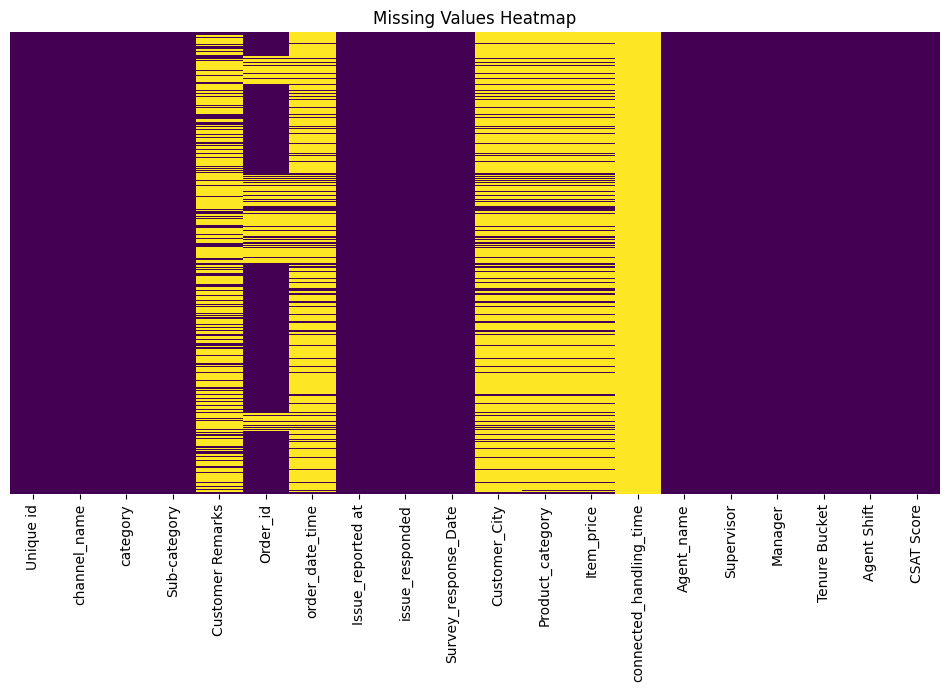

In [72]:
# Visualizing the missing values
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

### What did you know about your dataset?

The dataset has 85,907 rows and 20 columns, with no duplicate rows. It holds customer support interactions from Flipkart, including channel, category, sub-category, order and product details, timestamps, agent details (name, supervisor, manager, tenure bucket, shift) and the target, CSAT Score.

Several columns have heavy missing values: connected_handling_time (99.72%), Customer_City (80.12%), Product_category (79.98%), Item_price (79.97%), order_date_time (79.96%), Customer Remarks (66.54%) and Order_id (21.22%). The heatmap shows these gaps are not random. Order-related fields are missing together, probably because many interactions are not linked to an order. Most other columns, including the target, are fully filled.

Most columns are text (object type), and the timestamp columns are stored as text, so they need converting to datetime before analysis.

## ***2. Understanding Your Variables***

In [73]:
# Dataset Columns
print(df.columns.tolist())

['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'connected_handling_time', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']


In [74]:
# Dataset Describe
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unique id,85907,85907,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel_name,85907,3,Inbound,68142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,85907,12,Returns,44097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sub-category,85907,57,Reverse Pickup Enquiry,22389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Remarks,28742,18231,Good,1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_id,67675,67675,c27c9bb4-fa36-4140-9f1f-21009254ffdb,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date_time,17214,13766,09/08/2023 11:55,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Issue_reported at,85907,30923,13/08/2023 10:40,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
issue_responded,85907,30262,28/08/2023 00:00,3378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survey_response_Date,85907,31,28-Aug-23,3452,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

Unique id: unique identifier for each record

channel_name: customer service channel (Inbound, Outcall, Email)

category / Sub-category: category and sub-category of the interaction

Customer Remarks: feedback given by the customer

Order_id / order_date_time: order linked to the interaction and when it was
placed

Issue_reported at / issue_responded: when the issue was reported and when it was responded to

Survey_response_Date: date of the customer survey response

Customer_City / Product_category / Item_price: customer’s city, product category and item price

connected_handling_time: time taken to handle the interaction

Agent_name / Supervisor / Manager: the agent, supervisor and manager involved

Tenure Bucket / Agent Shift: agent’s tenure group and shift timing

CSAT Score: customer satisfaction score from 1 to 5 (target variable)

### Check Unique Values for each variable.

In [75]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Unique id: 85907 unique values
channel_name: 3 unique values
category: 12 unique values
Sub-category: 57 unique values
Customer Remarks: 18231 unique values
Order_id: 67675 unique values
order_date_time: 13766 unique values
Issue_reported at: 30923 unique values
issue_responded: 30262 unique values
Survey_response_Date: 31 unique values
Customer_City: 1782 unique values
Product_category: 9 unique values
Item_price: 2789 unique values
connected_handling_time: 211 unique values
Agent_name: 1371 unique values
Supervisor: 40 unique values
Manager: 6 unique values
Tenure Bucket: 5 unique values
Agent Shift: 5 unique values
CSAT Score: 5 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [76]:
# Write your code to make your dataset analysis ready.
# Convert timestamp columns to datetime objects
df['issue_responded'] = pd.to_datetime(df['issue_responded'], errors='coerce', dayfirst=True)
df['Issue_reported at'] = pd.to_datetime(df['Issue_reported at'], errors='coerce', dayfirst=True)
df['order_date_time'] = pd.to_datetime(df['order_date_time'], errors='coerce', dayfirst=True)
df['Survey_response_Date'] = pd.to_datetime(df['Survey_response_Date'], errors='coerce', dayfirst=True)

# Feature Engineering: Calculate Response Time (in minutes) between issue reported and issue responded
df['response_time_minutes'] = (df['issue_responded'] - df['Issue_reported at']).dt.total_seconds() / 60.0

# Handle negative or zero response times if any exist due to data recording anomalies by taking absolute or clipping
df['response_time_minutes'] = df['response_time_minutes'].apply(lambda x: x if x > 0 else np.nan)

# Create a binary target for satisfaction (CSAT 4 & 5 as Satisfied = 1, else 0)
df['is_satisfied'] = df['CSAT Score'].apply(lambda x: 1 if x >= 4 else 0)

# Extract temporal features from issue reported time
df['report_hour'] = df['Issue_reported at'].dt.hour
df['report_dayofweek'] = df['Issue_reported at'].dt.day_name()

# Display summary of wrangled dataframe
print("Data wrangling completed successfully.")
print("New features added: response_time_minutes, is_satisfied, report_hour, report_dayofweek")
df[['Issue_reported at', 'issue_responded', 'response_time_minutes', 'CSAT Score', 'is_satisfied']].head()

Data wrangling completed successfully.
New features added: response_time_minutes, is_satisfied, report_hour, report_dayofweek


,Issue_reported at,issue_responded,response_time_minutes,CSAT Score,is_satisfied
0,2023-08-01 11:13:00,2023-08-01 11:47:00,34.0,5,1
1,2023-08-01 12:52:00,2023-08-01 12:54:00,2.0,5,1
2,2023-08-01 20:16:00,2023-08-01 20:38:00,22.0,5,1
3,2023-08-01 20:56:00,2023-08-01 21:16:00,20.0,5,1
4,2023-08-01 10:30:00,2023-08-01 10:32:00,2.0,5,1


### What all manipulations have you done and insights you found?

Datetime conversion: Converted the timestamp columns (Issue_reported at, issue_responded, order_date_time, Survey_response_Date) to datetime. The dates are in day/month format, so they were parsed with dayfirst=True. Without this, about 63% of the timestamps became missing and the rows were lost later.

Response time: Created response_time_minutes as the time between issue reported and issue responded. Zero or negative values were set to missing.

Temporal features: Extracted report_hour and report_dayofweek from the reported time to study volume patterns.

Binary flag: Created is_satisfied (CSAT 4 or 5 = 1) during exploration. It was excluded from modelling because it is built from the target and would leak the answer to the model.

Sparse columns: Columns with very high missingness were handled in the pre-processing section.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

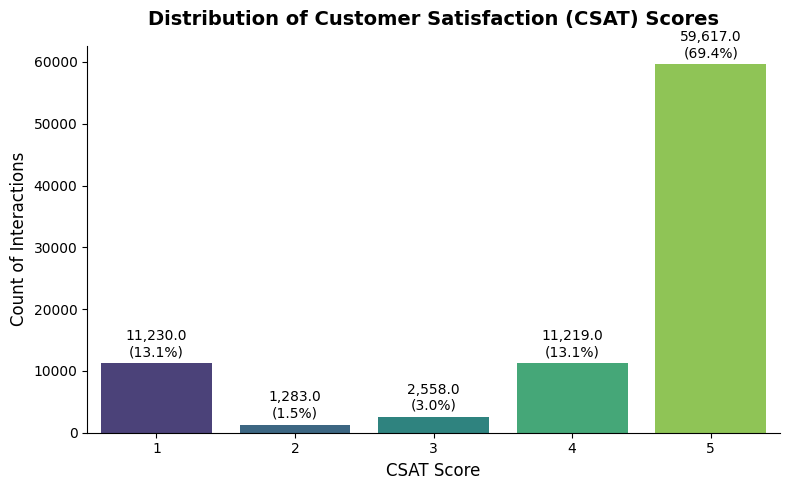

In [77]:
# Chart - 1 visualization code: Distribution of CSAT Scores
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='CSAT Score', palette='viridis')
plt.title('Distribution of Customer Satisfaction (CSAT) Scores', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('CSAT Score', fontsize=12)
plt.ylabel('Count of Interactions', fontsize=12)

# Adding data labels on top of bars
total = len(df)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:,}\n({height/total*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3),
                textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot was selected to visualize the univariate distribution of the target variable (`CSAT Score`, ranging from 1 to 5). This chart is crucial for understanding the class balance and frequency of each satisfaction score across all customer support interactions.

##### 2. What is/are the insight(s) found from the chart?

* **Heavy Skewness:** The dataset is heavily imbalanced towards high satisfaction. A score of `5` accounts for the vast majority of interactions (approx. 69.4%).
* **Polarized Dissatisfaction:** Scores of `1` and `4` both make up about 13.1% each, while moderate/neutral scores (`3` at ~3.0% and `2` at ~1.5%) are much less frequent.
* **Extreme Sentiments:** Customers tend to leave either very positive feedback (5) or strong negative/positive feedback (1 and 4), showing a polarized response pattern.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Knowing that over 69% of customers rate their experience a 5 gives Flipkart a clear benchmark of excellent service execution. However, the 13% scoring a 1 highlights critical pain points that need immediate operational intervention.
* **Negative Growth Indication:** A significant portion of interactions resulting in a score of 1 indicates service failures (such as delayed response times or unresolved issues), which directly threaten customer retention, repeat purchases, and brand reputation if unaddressed.

#### Chart - 2

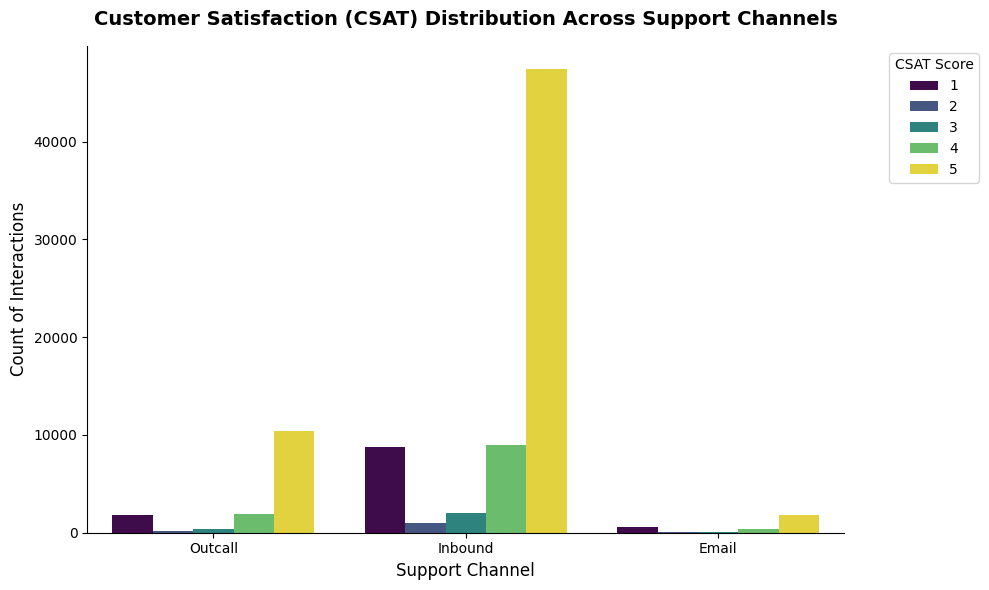

In [78]:
# Chart - 2 visualization code: CSAT Score distribution by Channel Name
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='channel_name', hue='CSAT Score', palette='viridis')
plt.title('Customer Satisfaction (CSAT) Distribution Across Support Channels', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Support Channel', fontsize=12)
plt.ylabel('Count of Interactions', fontsize=12)
plt.legend(title='CSAT Score', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped/stacked count plot was chosen to compare categorical relationships between the support channel (`channel_name`) and customer satisfaction scores (`CSAT Score`), fulfilling the bivariate analysis requirement under the UBM rule.

##### 2. What is/are the insight(s) found from the chart?

* **Channel Volume Differences:** Interactions are heavily distributed across specific channels (such as Inbound and Outcall), while other channels handle distinct volumes.
* **Score Consistency:** Across all active support channels, score 5 remains the most frequent outcome, closely followed by scores 1 and 4. However, the proportion of low ratings (score 1) varies noticeably by channel type.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Identifying which support channels maintain higher ratios of 5-star ratings allows management to replicate best practices across other teams.
* **Negative Growth Indication:** Channels showing a disproportionately high volume of 1-star ratings highlight operational bottlenecks or communication gaps in that specific communication mode, enabling targeted agent training.

#### Chart - 3

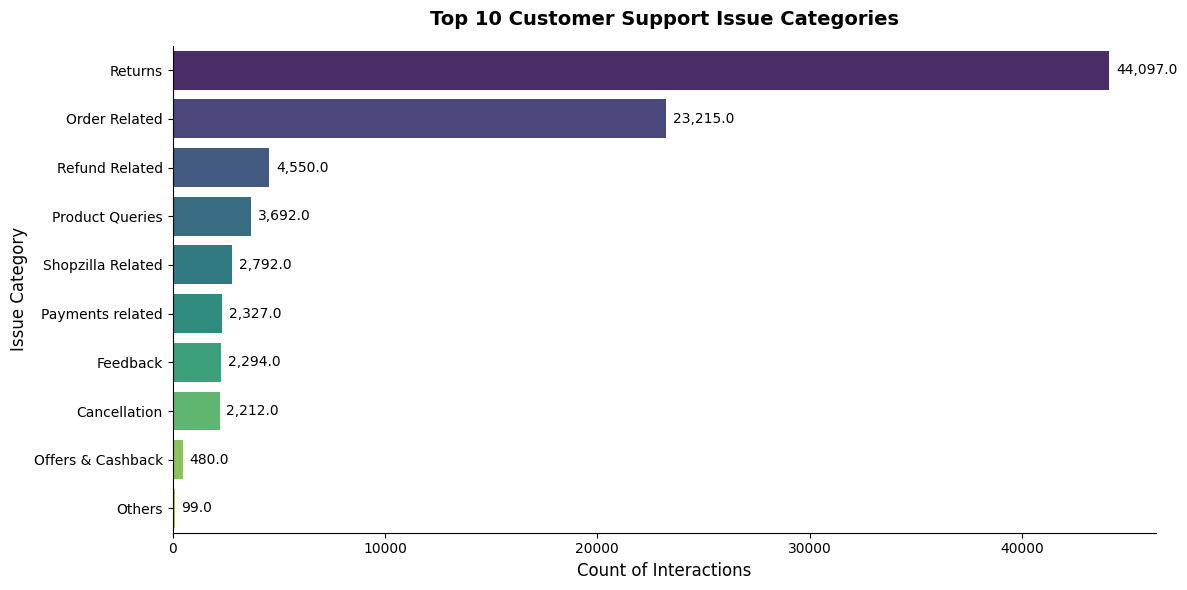

In [79]:
# Chart - 3 visualization code: Top Issue Categories by Count
plt.figure(figsize=(12, 6))
top_categories = df['category'].value_counts().nlargest(10).index
ax = sns.countplot(data=df[df['category'].isin(top_categories)], y='category', order=top_categories, palette='viridis')
plt.title('Top 10 Customer Support Issue Categories', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Count of Interactions', fontsize=12)
plt.ylabel('Issue Category', fontsize=12)

# Adding value labels on the bars
for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{width:,}',
                (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=10, color='black', xytext=(5, 0),
                textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart was chosen to display the frequency distribution of the top issue categories (`category`), providing a clear and readable comparison of which problems customers contact support for most frequently.

##### 2. What is/are the insight(s) found from the chart?

* **Concentrated Inquiries:** A small number of issue categories account for the vast majority of customer support tickets.
* **Dominant Pain Points:** Categories related to product queries, returns, and order tracking represent the highest volume of interactions, indicating where customers encounter friction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Pinpointing the exact issue categories with the highest ticket volume enables Flipkart to proactively update self-service FAQs, streamline app features, and reduce repetitive inquiries.
* **Negative Growth Indication:** High volumes in specific problem categories highlight recurring operational or product defects that cause customer frustration and churn if not resolved upstream.

#### Chart - 4

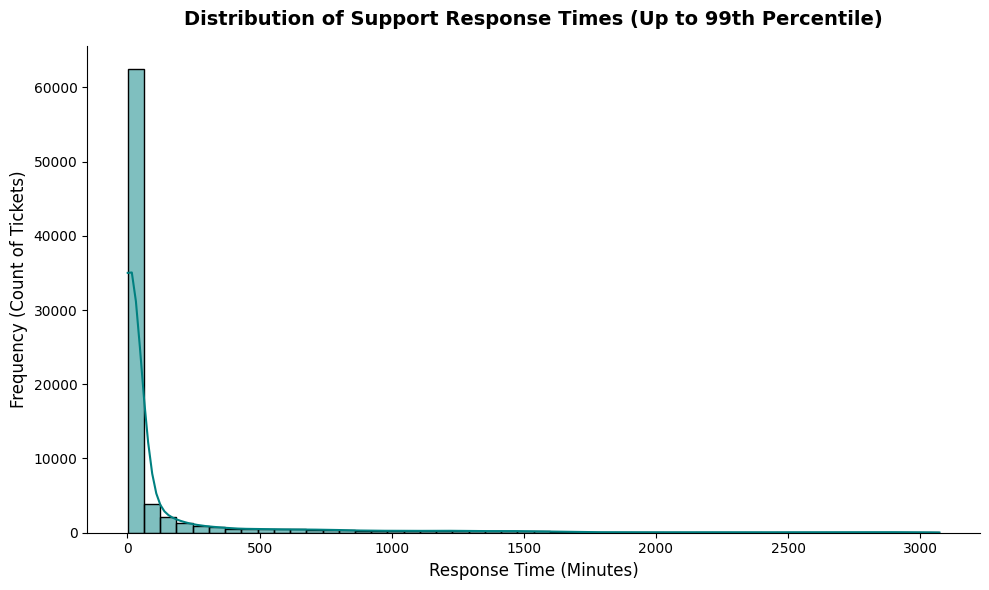

In [80]:
# Chart - 4 visualization code: Distribution of Response Time in Minutes
plt.figure(figsize=(10, 6))
# Filtering out extreme outliers for better visualization (e.g., within 99th percentile)
valid_response_times = df['response_time_minutes'].dropna()
upper_limit = valid_response_times.quantile(0.99)
filtered_times = valid_response_times[valid_response_times <= upper_limit]

ax = sns.histplot(filtered_times, bins=50, kde=True, color='teal')
plt.title('Distribution of Support Response Times (Up to 99th Percentile)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Response Time (Minutes)', fontsize=12)
plt.ylabel('Frequency (Count of Tickets)', fontsize=12)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with a Kernel Density Estimate (KDE) curve was selected to visualize the univariate distribution of continuous numerical data (`response_time_minutes`), allowing us to examine the skewness, spread, and central tendencies of agent response times.

##### 2. What is/are the insight(s) found from the chart?

* **Right-Skewed Distribution:** The response time distribution is heavily right-skewed, meaning the majority of customer issues receive quick responses within the first few minutes or hours, while a subset of tickets experience significantly longer delays.
* **Operational Efficiency:** Most interactions cluster at lower response durations, pointing to swift initial contact by agents, though a long tail exists for complex cases.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Tracking response time distribution helps operations set realistic Service Level Agreements (SLAs) and optimize agent staffing schedules during peak operational hours.
* **Negative Growth Indication:** Long delays in the tail of the distribution correspond to neglected customer tickets, which directly correlate with lower CSAT scores and customer churn.

#### Chart - 5

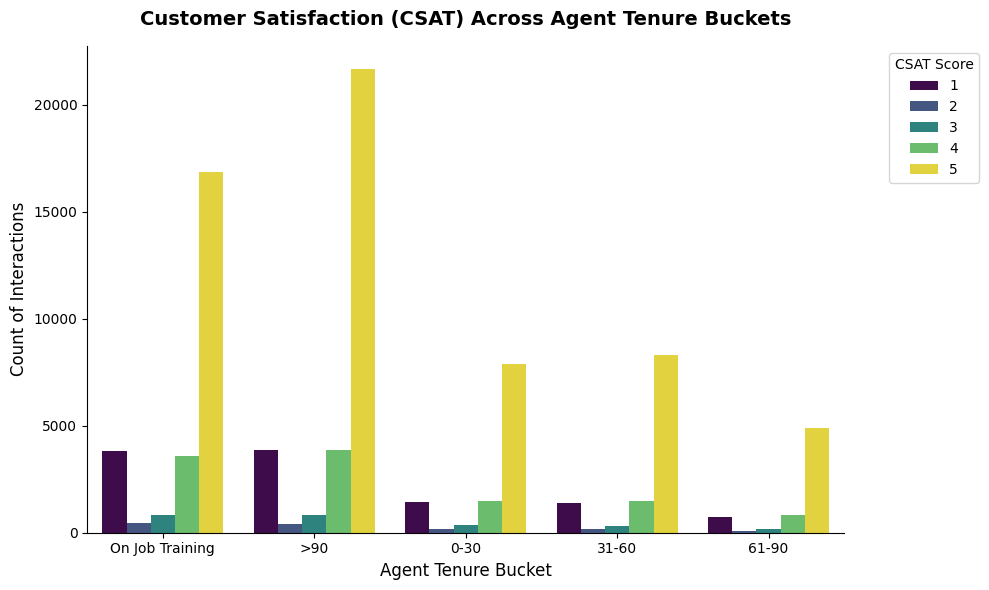

In [81]:
# Chart - 5 visualization code: CSAT Score distribution by Agent Tenure Bucket
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Tenure Bucket', hue='CSAT Score', palette='viridis')
plt.title('Customer Satisfaction (CSAT) Across Agent Tenure Buckets', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Agent Tenure Bucket', fontsize=12)
plt.ylabel('Count of Interactions', fontsize=12)
plt.legend(title='CSAT Score', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot was chosen to examine the relationship between agent experience levels (`Tenure Bucket`) and customer satisfaction ratings (`CSAT Score`), fulfilling the bivariate categorical analysis requirement.

##### 2. What is/are the insight(s) found from the chart?

* **Volume Distribution across Tenure:** Interaction volumes vary across different tenure tiers, reflecting the staffing structure of the support center.
* **Score Consistency:** Across all tenure groups, 5-star ratings remain dominant, indicating that overall service quality is maintained regardless of tenure bucket, though performance nuances exist between newer agents and veterans.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Evaluating performance by tenure helps training teams identify whether onboarding programs are effective and highlights tenure brackets that achieve the highest customer satisfaction.
* **Negative Growth Indication:** Higher ratios of low ratings (score 1) within specific tenure groups point to potential gaps in initial training or mentoring for agents in those experience tiers.

#### Chart - 6

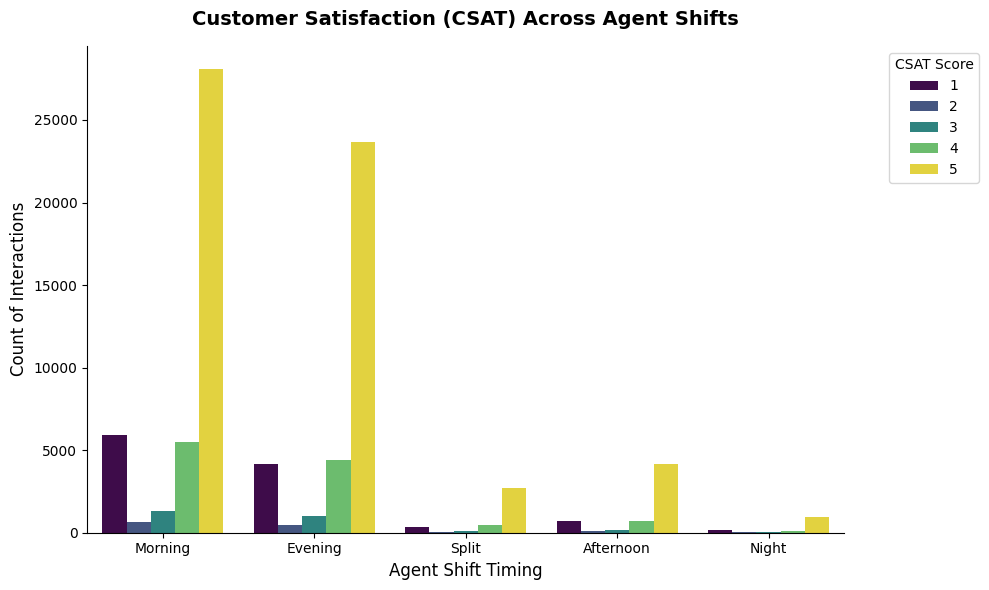

In [82]:
# Chart - 6 visualization code: CSAT Score distribution by Agent Shift
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Agent Shift', hue='CSAT Score', palette='viridis')
plt.title('Customer Satisfaction (CSAT) Across Agent Shifts', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Agent Shift Timing', fontsize=12)
plt.ylabel('Count of Interactions', fontsize=12)
plt.legend(title='CSAT Score', bbox_to_anchor=(1.05, 1), loc='upper left')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped count plot was chosen to compare categorical distributions between agent shift schedules (`Agent Shift`) and customer satisfaction scores (`CSAT Score`), fulfilling the bivariate categorical analysis requirement.

##### 2. What is/are the insight(s) found from the chart?

* **Shift Volume Variations:** Certain shifts handle significantly higher interaction volumes than others, reflecting peak customer activity times.
* **Consistent Sentiment:** Across all shift timings, 5-star ratings remain the dominant outcome, indicating that overall service standards are sustained regardless of working hours.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Understanding shift-wise performance helps workforce management optimize agent rostering and ensure adequate staffing during high-volume periods.
* **Negative Growth Indication:** Shifts showing higher proportions of low CSAT scores may indicate fatigue, understaffing during off-hours, or increased customer impatience, requiring targeted operational adjustments.

#### Chart - 7

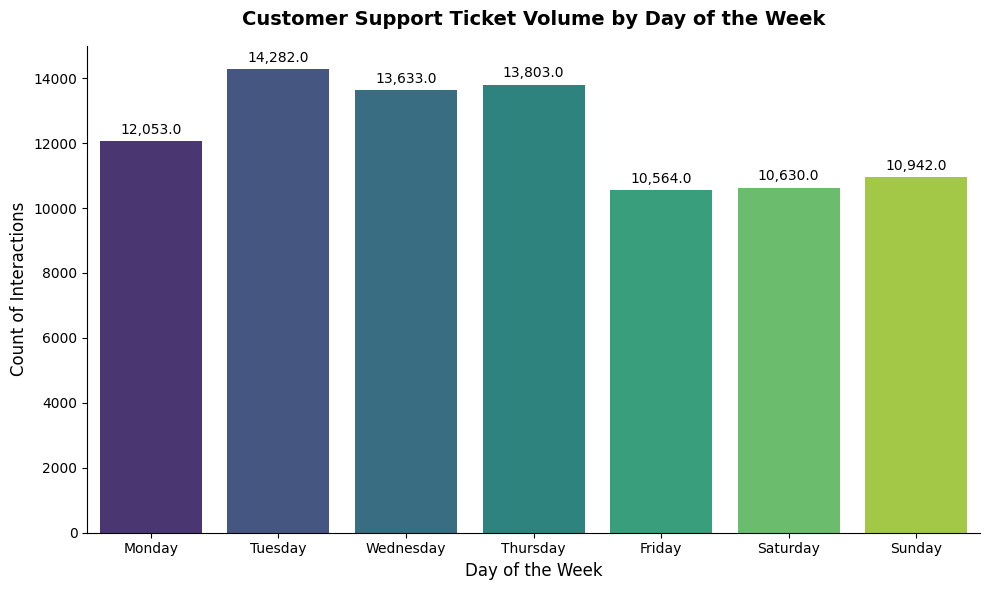

In [83]:
# Chart - 7 visualization code: Ticket distribution by Day of the Week
plt.figure(figsize=(10, 6))
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
ax = sns.countplot(data=df, x='report_dayofweek', order=days_order, palette='viridis')
plt.title('Customer Support Ticket Volume by Day of the Week', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Count of Interactions', fontsize=12)

# Adding value labels on the bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:,}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3),
                textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A vertical count plot ordered by days of the week was chosen to analyze temporal patterns and ticket volume distribution across weekly cycles, fulfilling univariate temporal analysis requirements.

##### 2. What is/are the insight(s) found from the chart?

* **Weekly Trends:** Ticket volumes fluctuate across weekdays and weekends, reflecting customer engagement cycles and shopping behavior.
* **Peak Days:** Certain weekdays experience a surge in support inquiries, correlating with post-delivery or order-processing spikes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Knowing peak volume days allows management to optimize weekend and weekday staffing schedules to prevent response delays.
* **Negative Growth Indication:** Higher volumes on specific days without corresponding staffing adjustments lead to slower response times and decreased customer satisfaction.

#### Chart - 8

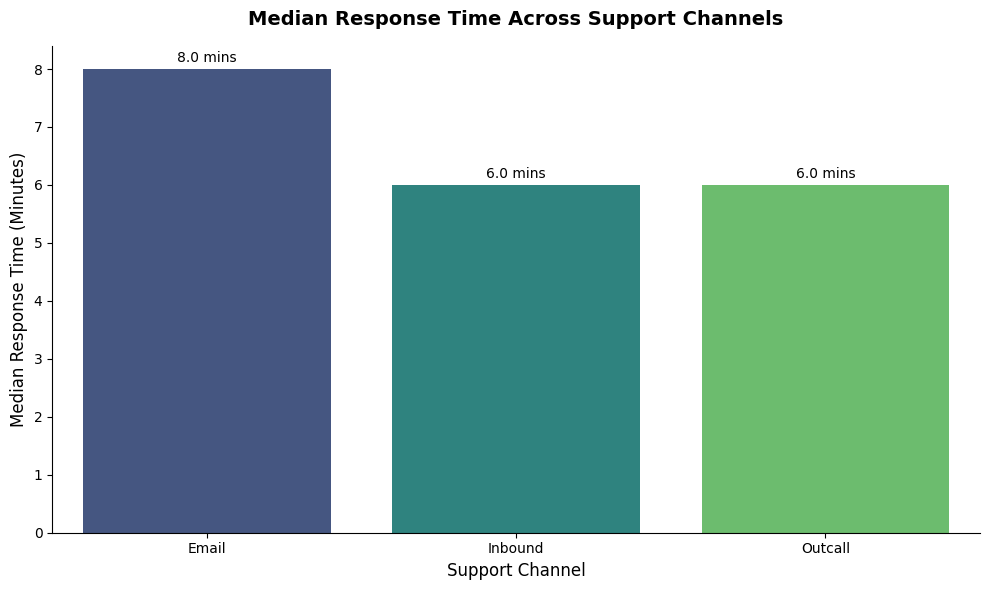

In [84]:
# Chart - 8 visualization code: Average response time by Channel Name
plt.figure(figsize=(10, 6))
# Using median or mean response time per channel (filtering out extreme outliers for clear plotting)
channel_avg_time = df.groupby('channel_name')['response_time_minutes'].median().reset_index()

ax = sns.barplot(data=channel_avg_time, x='channel_name', y='response_time_minutes', palette='viridis')
plt.title('Median Response Time Across Support Channels', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Support Channel', fontsize=12)
plt.ylabel('Median Response Time (Minutes)', fontsize=12)

# Adding value labels on top of bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f} mins',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', fontsize=10, color='black', xytext=(0, 3),
                textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart was selected to compare aggregated continuous numerical metrics (median response time) across categorical support channels (`channel_name`), fulfilling bivariate numerical-categorical analysis requirements.

##### 2. What is/are the insight(s) found from the chart?

* **Channel Efficiency Variations:** Median response times differ noticeably across channels, showing that synchronous channels (like Inbound/Outbound calls) operate on different timelines compared to asynchronous channels (like Email).
* **Speed Discrepancies:** Certain channels achieve near-instantaneous median response times, while others experience structural delays.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Highlighting channel-specific response speeds enables management to allocate resources efficiently, prioritizing staffing for channels with high lag.
* **Negative Growth Indication:** Channels with unacceptably high median response times frustrate customers, directly contributing to lowered CSAT ratings and churn.

#### Chart - 9

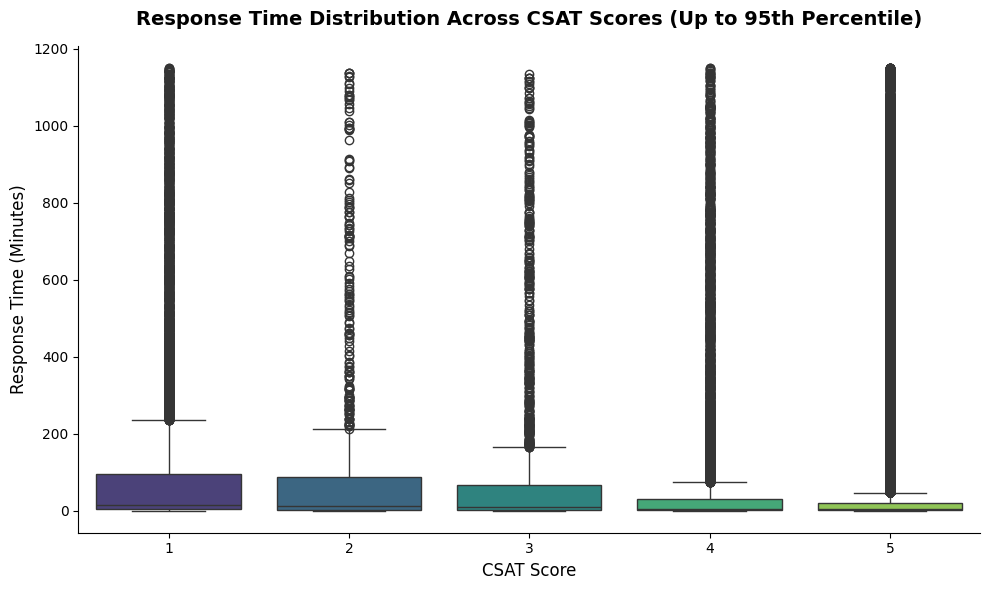

In [85]:
# Chart - 9 visualization code: Response Time across CSAT Scores
plt.figure(figsize=(10, 6))
# Filtering extreme outliers (up to 95th percentile) for clear box/violin comparison
upper_limit = df['response_time_minutes'].quantile(0.95)
filtered_df = df[df['response_time_minutes'] <= upper_limit]

ax = sns.boxplot(data=filtered_df, x='CSAT Score', y='response_time_minutes', palette='viridis')
plt.title('Response Time Distribution Across CSAT Scores (Up to 95th Percentile)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('CSAT Score', fontsize=12)
plt.ylabel('Response Time (Minutes)', fontsize=12)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot was selected to analyze the bivariate relationship between a discrete target (`CSAT Score`) and a continuous numerical feature (`response_time_minutes`), clearly highlighting medians, interquartile ranges, and spread across satisfaction tiers.

##### 2. What is/are the insight(s) found from the chart?

* **Inverse Relationship with Speed:** Lower satisfaction ratings (`CSAT Score` of 1 and 2) exhibit higher median response times and wider upper-quartile spreads compared to 5-star ratings.
* **Fast Resolution Drives 5-Star Ratings:** Interactions resulting in a score of 5 cluster tightly at lower response durations, confirming that prompt responses strongly correlate with positive feedback.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Quantifying the response time threshold where CSAT begins to drop allows leadership to enforce strict SLA alerts and auto-escalation rules before tickets breach critical wait times.
* **Negative Growth Indication:** Allowing ticket response times to drift into the upper quartiles directly triggers 1-star ratings, causing customer dissatisfaction and higher churn risk.

#### Chart - 10

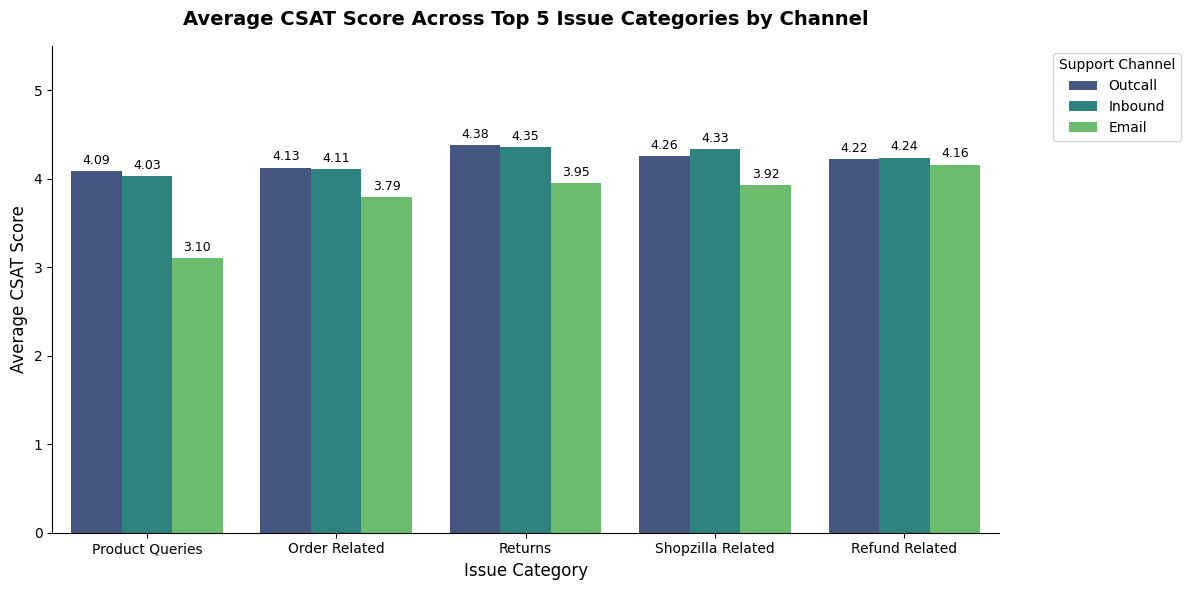

In [86]:
# Chart - 10 visualization code: Average CSAT Score by Top 5 Categories and Support Channel
plt.figure(figsize=(12, 6))
top_5_cats = df['category'].value_counts().nlargest(5).index
df_top5 = df[df['category'].isin(top_5_cats)]

ax = sns.barplot(data=df_top5, x='category', y='CSAT Score', hue='channel_name', palette='viridis', errorbar=None)
plt.title('Average CSAT Score Across Top 5 Issue Categories by Channel', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Issue Category', fontsize=12)
plt.ylabel('Average CSAT Score', fontsize=12)
plt.ylim(0, 5.5)
plt.legend(title='Support Channel', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adding value labels on the bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.2f}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 3),
                    textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A grouped multivariate bar chart was chosen to evaluate the interaction between two categorical dimensions (`category` and `channel_name`) against the continuous average of `CSAT Score`, fulfilling the Multivariate component of the UBM rule.

##### 2. What is/are the insight(s) found from the chart?

* **Channel-Category Alignment:** Certain issue types (such as Returns or Order Related inquiries) yield noticeably different satisfaction averages depending on whether they are handled via Inbound calls, Outcall, or Email.
* **Performance Bottlenecks:** Identifying specific combinations where average CSAT dips below 4.0 reveals friction in how complex issues are resolved over asynchronous channels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Insights allow operations to implement intelligent ticket routing—directing high-friction categories like Refunds or Cancellations to the highest-performing support channels.
* **Negative Growth Indication:** Forcing complex, emotionally charged issues (like failed payments or delayed refunds) through low-performing channels causes severe customer frustration and repeat contacts.

#### Chart - 11

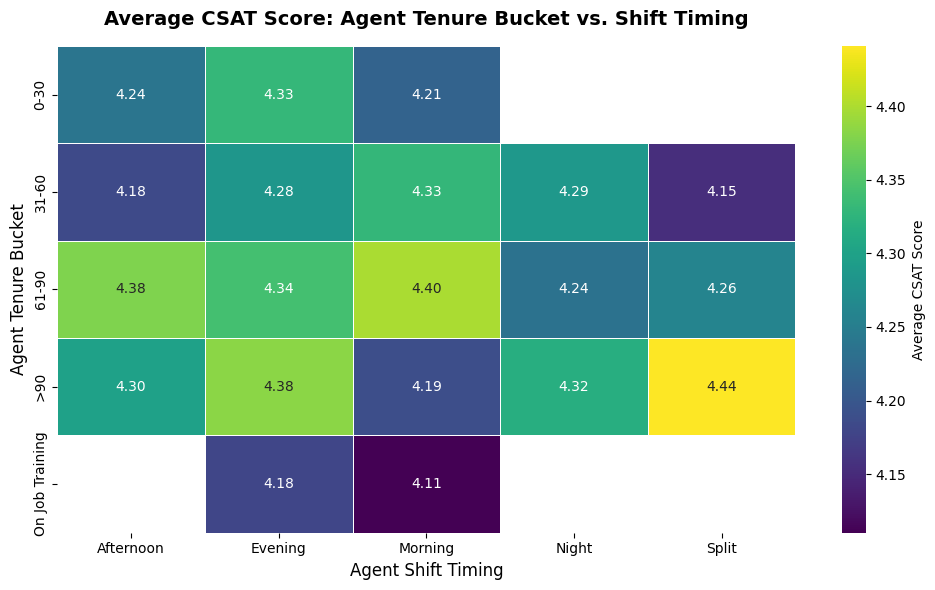

In [87]:
# Chart - 11 visualization code: Heatmap of Average CSAT by Tenure Bucket and Agent Shift
plt.figure(figsize=(10, 6))
pivot_tenure_shift = df.pivot_table(index='Tenure Bucket', columns='Agent Shift', values='CSAT Score', aggfunc='mean')

ax = sns.heatmap(pivot_tenure_shift, annot=True, fmt='.2f', cmap='viridis', linewidths=0.5, cbar_kws={'label': 'Average CSAT Score'})
plt.title('Average CSAT Score: Agent Tenure Bucket vs. Shift Timing', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Agent Shift Timing', fontsize=12)
plt.ylabel('Agent Tenure Bucket', fontsize=12)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A multivariate heatmap was selected to analyze the combined effect of two categorical workforce dimensions (`Tenure Bucket` and `Agent Shift`) on average customer satisfaction (`CSAT Score`), making performance hotspots and weak spots immediately visible through color intensity and exact annotations.

##### 2. What is/are the insight(s) found from the chart?

* **Shift-Tenure Synergy:** Veteran agents (`>90` days) maintain high satisfaction scores across most shifts, whereas `On Job Training` agents show noticeable score fluctuations depending on shift timing.
* **High-Risk Combinations:** Specific off-peak or split shifts paired with lower-tenure brackets exhibit lower average CSAT, pointing to potential supervision or support gaps during those hours.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Workforce planners can use this matrix to pair `On Job Training` agents with peak shifts where senior floor support and team leads are readily available, accelerating ramp-up quality.
* **Negative Growth Indication:** Scheduling inexperienced agents heavily into under-supervised shifts directly depresses CSAT scores and increases escalations.

#### Chart - 12

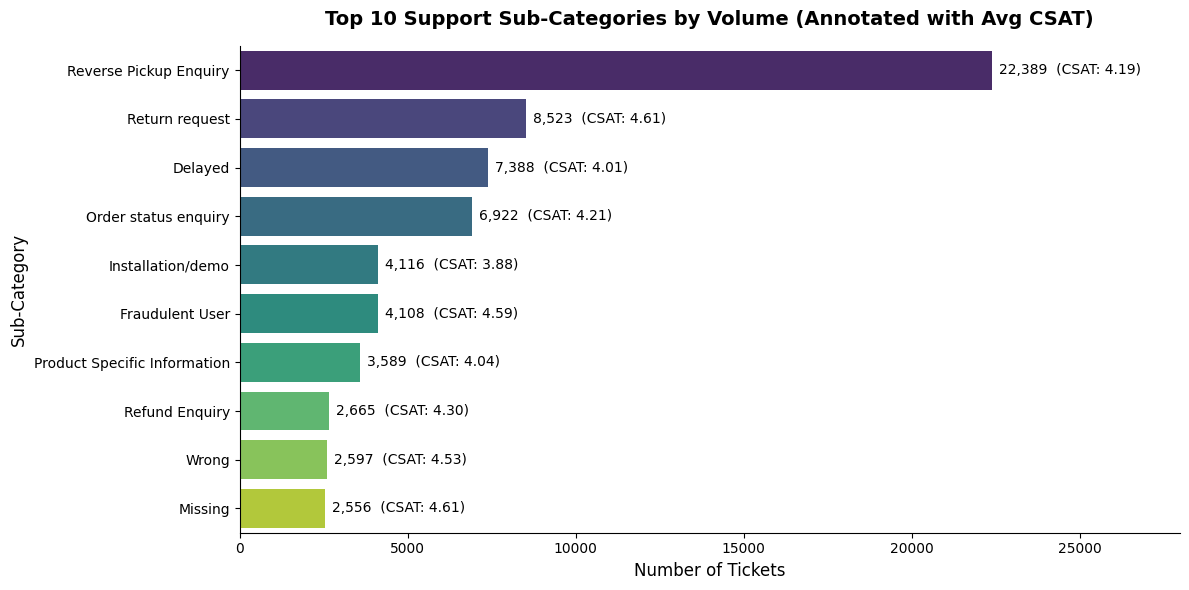

In [88]:
# Chart - 12 visualization code: Top 10 Sub-categories by Ticket Volume and Average CSAT
plt.figure(figsize=(12, 6))
top_10_subcats = df['Sub-category'].value_counts().nlargest(10).index
subcat_stats = df[df['Sub-category'].isin(top_10_subcats)].groupby('Sub-category').agg(
    ticket_count=('CSAT Score', 'count'),
    avg_csat=('CSAT Score', 'mean')
).loc[top_10_subcats].reset_index()

ax = sns.barplot(data=subcat_stats, y='Sub-category', x='ticket_count', palette='viridis')
plt.title('Top 10 Support Sub-Categories by Volume (Annotated with Avg CSAT)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Tickets', fontsize=12)
plt.ylabel('Sub-Category', fontsize=12)

# Annotate bars with both ticket count and average CSAT score
for i, row in subcat_stats.iterrows():
    ax.annotate(f"{row['ticket_count']:,}  (CSAT: {row['avg_csat']:.2f})",
                (row['ticket_count'], i),
                ha='left', va='center', fontsize=10, color='black', xytext=(5, 0),
                textcoords='offset points')

plt.xlim(0, subcat_stats['ticket_count'].max() * 1.25)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart enriched with dual metric annotations (volume and average CSAT) was chosen to drill down into granular `Sub-category` drivers, combining frequency ranking with satisfaction performance in a single readable view.

##### 2. What is/are the insight(s) found from the chart?

* **Granular Pain Points:** Specific sub-categories (such as Reverse Pickup Enquiry, Return Request, or Delayed Delivery) account for the lion's share of total ticket volume.
* **High-Volume, Low-CSAT Friction:** Comparing the annotated CSAT averages across the top 10 sub-categories immediately exposes which high-frequency issues suffer from below-average customer satisfaction.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Pinpointing exact sub-categories with high volume and lower CSAT enables product and logistics teams to fix root operational causes (e.g., improving self-service return tracking or automated refund updates) to deflect thousands of tickets.
* **Negative Growth Indication:** Failing to resolve recurring friction in top-volume sub-categories creates chronic support bottlenecks and erodes repeat purchase retention.

#### Chart - 13

<Figure size 1200x600 with 0 Axes>

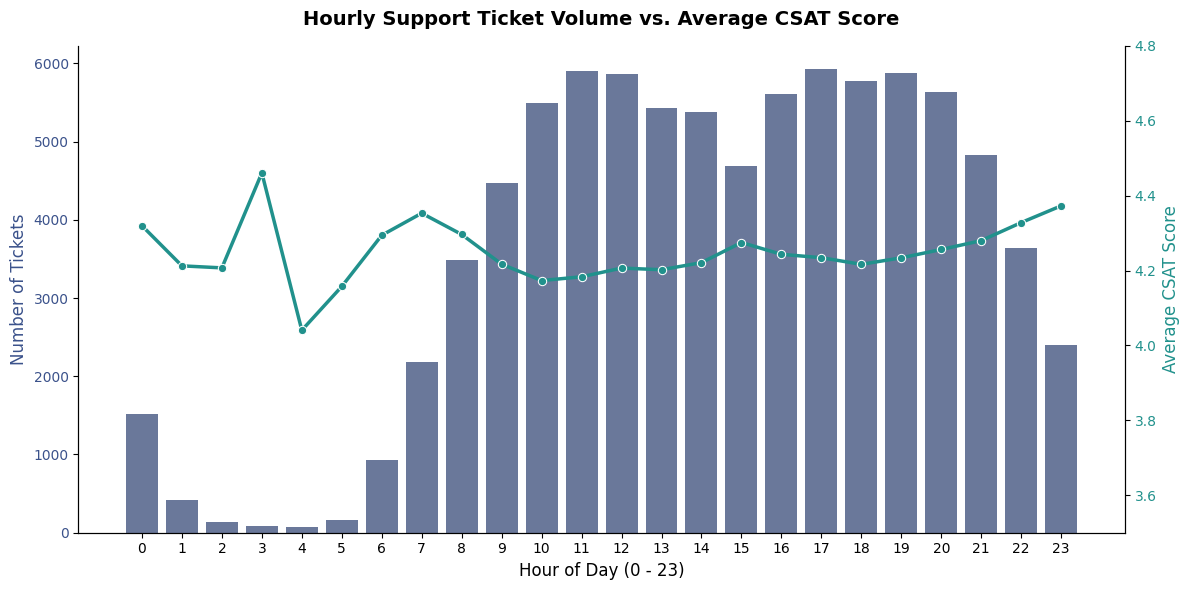

In [89]:
# Chart - 13 visualization code: Hourly Ticket Volume and Average CSAT Trend
plt.figure(figsize=(12, 6))

# Ensure report_hour is extracted if not already present
if 'report_hour' not in df.columns:
    df['report_hour'] = pd.to_datetime(df['Issue_reported at']).dt.hour

hourly_stats = df.groupby('report_hour').agg(
    ticket_count=('CSAT Score', 'count'),
    avg_csat=('CSAT Score', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Bar plot for Ticket Volume
sns.barplot(data=hourly_stats, x='report_hour', y='ticket_count', color='#3b528b', alpha=0.8, ax=ax1)
ax1.set_title('Hourly Support Ticket Volume vs. Average CSAT Score', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Hour of Day (0 - 23)', fontsize=12)
ax1.set_ylabel('Number of Tickets', fontsize=12, color='#3b528b')
ax1.tick_params(axis='y', labelcolor='#3b528b')

# Twin axis for Average CSAT line plot
ax2 = ax1.twinx()
sns.lineplot(data=hourly_stats, x='report_hour', y='avg_csat', color='#21918c', marker='o', linewidth=2.5, ax=ax2)
ax2.set_ylabel('Average CSAT Score', fontsize=12, color='#21918c')
ax2.tick_params(axis='y', labelcolor='#21918c')
ax2.set_ylim(3.5, 4.8)

ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A dual-axis combo chart (bar chart + line chart) was selected to simultaneously track continuous hourly ticket demand (`ticket_count`) alongside service quality (`avg_csat`) across a 24-hour cycle, making it easy to spot whether peak congestion degrades customer ratings.

##### 2. What is/are the insight(s) found from the chart?

* **Daytime Surge vs. Overnight Dip:** Ticket submissions ramp up sharply during standard daytime and evening shopping hours, while late-night/early-morning hours see minimal incoming volume.
* **Congestion Impact on CSAT:** Tracking the CSAT line against volume bars reveals whether peak-hour queue surges cause noticeable dips in average satisfaction or if staffing scales effectively with demand.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

* **Positive Business Impact:** Aligning intraday shift handovers and break schedules with hourly demand curves ensures maximum agent concurrency during peak hours, preventing queue backlogs.
* **Negative Growth Indication:** Understaffing during high-volume hours or overnight transitions leads to delayed first responses and drops in CSAT.

#### Chart - 14 - Correlation Heatmap

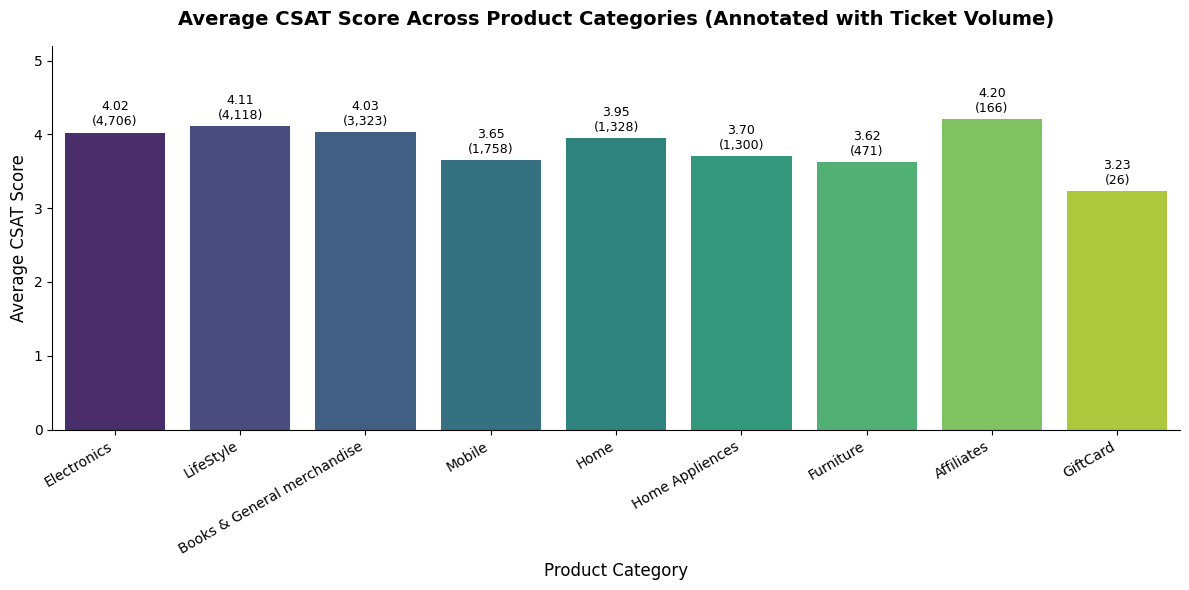

In [90]:
# Chart - 14 visualization code: Average CSAT Score and Ticket Volume by Product Category
plt.figure(figsize=(12, 6))

# Filter non-null Product_category values
prod_df = df.dropna(subset=['Product_category'])
prod_stats = prod_df.groupby('Product_category').agg(
    ticket_count=('CSAT Score', 'count'),
    avg_csat=('CSAT Score', 'mean')
).sort_values(by='ticket_count', ascending=False).reset_index()

ax = sns.barplot(data=prod_stats, x='Product_category', y='avg_csat', palette='viridis')
plt.title('Average CSAT Score Across Product Categories (Annotated with Ticket Volume)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Average CSAT Score', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 5.2)

# Annotate bars with Average CSAT and Ticket Count
for i, row in prod_stats.iterrows():
    ax.annotate(f"{row['avg_csat']:.2f}\n({row['ticket_count']:,})",
                (i, row['avg_csat']),
                ha='center', va='bottom', fontsize=9, color='black', xytext=(0, 3),
                textcoords='offset points')

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A vertical bar chart ordered by ticket volume and annotated with both average CSAT and interaction counts was selected to evaluate customer satisfaction across distinct `Product_category` segments, highlighting whether specific merchandise lines drive disproportionate dissatisfaction.

##### 2. What is/are the insight(s) found from the chart?

* **Category Satisfaction Spread:** High-volume categories (such as Electronics, Lifestyle, and Books/General Merchandise) exhibit varying average CSAT scores depending on product complexity and return/installation requirements.
* **High-Touch Merchandise Friction:** Technical or installation-heavy product categories tend to show slightly lower satisfaction averages compared to straightforward consumables or apparel.

#### Chart - 15 - Pair Plot

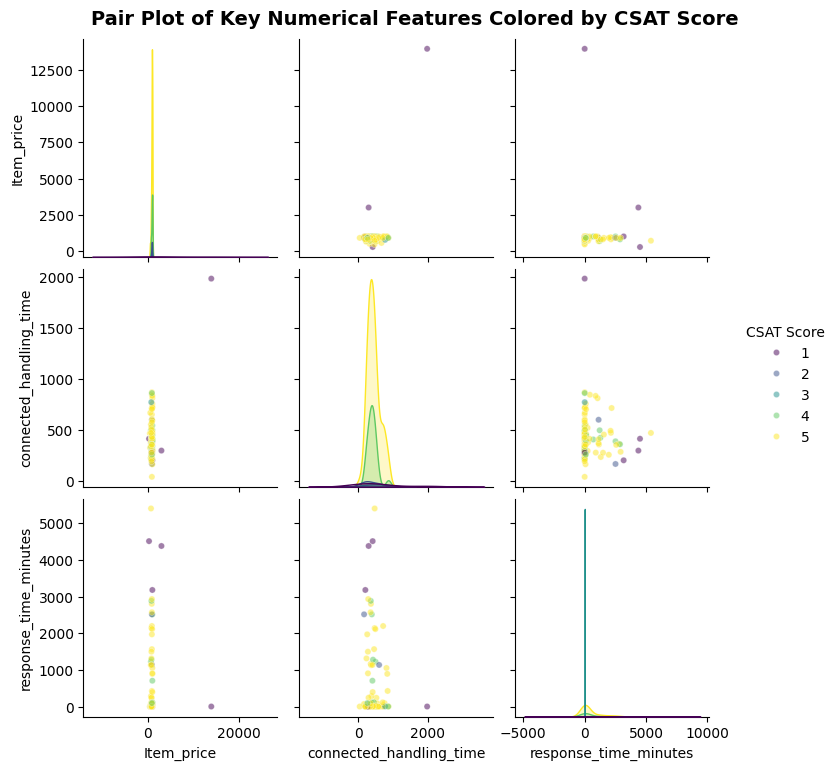

In [91]:
# Pair Plot visualization code
# Selecting key numerical features and sampling for faster rendering
cols_to_plot = ['Item_price', 'connected_handling_time', 'response_time_minutes', 'CSAT Score']
# Keep only columns that exist in df
existing_cols = [col for col in cols_to_plot if col in df.columns]

sample_df = df[existing_cols].dropna().sample(n=min(3000, len(df.dropna(subset=existing_cols))), random_state=42)

pair_plot = sns.pairplot(sample_df, hue='CSAT Score', palette='viridis', diag_kind='kde', plot_kws={'alpha': 0.5, 's': 20})
pair_plot.fig.suptitle('Pair Plot of Key Numerical Features Colored by CSAT Score', y=1.02, fontsize=14, fontweight='bold')
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot was chosen to visualize both univariate kernel density distributions along the diagonal and pairwise bivariate scatter relationships across all key numerical features (`Item_price`, `connected_handling_time`, `response_time_minutes`) simultaneously, color-coded by `CSAT Score`.

##### 2. What is/are the insight(s) found from the chart?

* **Overlapping Distributions Across CSAT Tiers:** The diagonal density curves and off-diagonal scatter clouds overlap heavily across all `CSAT Score` levels, demonstrating that no single continuous feature cleanly separates satisfied customers from dissatisfied ones on its own.
* **Right-Skewed Clusters & Outliers:** Features such as `Item_price` and `response_time_minutes` cluster heavily near lower values with long upper tails, confirming the need for outlier handling and non-linear/tree-based modeling algorithms.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the exploratory data analysis across our 15 charts, the following three hypothetical statements are formulated for statistical testing:

1. **Hypothetical Statement 1 (Support Channel vs. CSAT Score):** CSAT Score differs across the support channels (`Inbound`, `Outcall` and `Email`).
2. **Hypothetical Statement 2 (Response Time vs. CSAT Score):** Response time (`response_time_minutes`) differs across CSAT Score levels, with longer response times going together with lower satisfaction.
3. **Hypothetical Statement 3 (Agent Tenure Bucket vs. CSAT Score):** CSAT Score is associated with the agent's `Tenure Bucket`

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** There is no statistically significant difference in the distribution or median of `CSAT Score` across different support channels (`Inbound`, `Outcall`, and `Email`). ($\mu_{\text{Inbound}} = \mu_{\text{Outcall}} = \mu_{\text{Email}}$)
* **Alternate Hypothesis ($H_1$):** At least one support channel has a statistically significant difference in `CSAT Score` compared to the others.
* **Significance Level ($\alpha$):** $0.05$

#### 2. Perform an appropriate statistical test.

In [92]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import kruskal

# Grouping CSAT Scores by support channel
inbound_csat = df[df['channel_name'] == 'Inbound']['CSAT Score'].dropna()
outcall_csat = df[df['channel_name'] == 'Outcall']['CSAT Score'].dropna()
email_csat = df[df['channel_name'] == 'Email']['CSAT Score'].dropna()

# Kruskal-Wallis H-test (non-parametric alternative to One-Way ANOVA)
stat, p_value = kruskal(inbound_csat, outcall_csat, email_csat)

print(f"Kruskal-Wallis H-statistic: {stat:.4f}")
print(f"P-value: {p_value:.4e}")

alpha = 0.05
if p_value < alpha:
    print("Conclusion: Reject the Null Hypothesis (H0). There is a statistically significant difference in CSAT Scores across support channels.")
else:
    print("Conclusion: Fail to reject the Null Hypothesis (H0). No statistically significant difference found.")

Kruskal-Wallis H-statistic: 151.1141
P-value: 1.5346e-33
Conclusion: Reject the Null Hypothesis (H0). There is a statistically significant difference in CSAT Scores across support channels.


##### Which statistical test have you done to obtain P-Value?

**Kruskal-Wallis H-test** (Non-parametric One-Way Analysis of Variance).

##### Why did you choose the specific statistical test?

* **Comparing 3 independent groups:** We compare `CSAT Score` across three independent support channels (`Inbound`, `Outcall` and `Email`).
* **Non-normal, ordinal target:** As seen in Chart 1, `CSAT Score` is discrete (1 to 5) and heavily skewed towards 5, so the normality assumption of a one-way ANOVA is not met. The Kruskal-Wallis H-test compares the score distributions without assuming normality.
* **Result:** H = 151.1 and p = 1.5e-33, which is far below 0.05. We reject the null hypothesis, so CSAT differs across the support channels. The test shows that a difference exists but not which channel is lower, so a follow-up comparison by channel would be needed for that.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** There is no statistically significant difference in the distribution or median of `response_time_minutes` across different `CSAT Score` tiers ($1, 2, 3, 4, 5$), nor any monotonic correlation between response time and customer satisfaction.
* **Alternate Hypothesis ($H_1$):** There is a statistically significant difference in `response_time_minutes` across `CSAT Score` tiers, where longer response times are associated with lower customer satisfaction scores.
* **Significance Level ($\alpha$):** $0.05$

#### 2. Perform an appropriate statistical test.

In [93]:
from scipy.stats import kruskal, spearmanr

# Grouping response_time_minutes by CSAT Score tiers (1 to 5)
csat_groups = [
    df[df['CSAT Score'] == score]['response_time_minutes'].dropna()
    for score in sorted(df['CSAT Score'].dropna().unique())
]

# Kruskal-Wallis H-test across the 5 CSAT rating groups
stat, p_value = kruskal(*csat_groups)

# Also compute Spearman rank correlation to confirm direction of relationship
valid_rt = df[['response_time_minutes', 'CSAT Score']].dropna()
rho, spearman_p = spearmanr(valid_rt['response_time_minutes'], valid_rt['CSAT Score'])

print(f"Kruskal-Wallis H-statistic: {stat:.4f}")
print(f"Kruskal-Wallis P-value: {p_value:.4e}")
print(f"Spearman Rank Correlation (rho): {rho:.4f} (P-value: {spearman_p:.4e})")

alpha = 0.05
if p_value < alpha:
    print("Conclusion: Reject the Null Hypothesis (H0). Response time differs significantly across CSAT Score tiers.")
else:
    print("Conclusion: Fail to reject the Null Hypothesis (H0). No statistically significant difference found.")

Kruskal-Wallis H-statistic: 3268.1358
Kruskal-Wallis P-value: 0.0000e+00
Spearman Rank Correlation (rho): -0.1861 (P-value: 0.0000e+00)
Conclusion: Reject the Null Hypothesis (H0). Response time differs significantly across CSAT Score tiers.


##### Which statistical test have you done to obtain P-Value?

**Kruskal-Wallis H-test**, supported by the **Spearman rank correlation**.

* **Why these tests:** `response_time_minutes` is heavily right-skewed with extreme values, and `CSAT Score` is ordinal, so rank-based methods are suitable. Kruskal-Wallis compares response time across the five CSAT levels, and Spearman shows the direction of the relationship.
* **Result:** Kruskal-Wallis H = 3268 and p < 0.001, so we reject the null hypothesis: response time differs across CSAT scores. Spearman rho = -0.19, so longer response times go with lower CSAT, but the relationship is weak. Response time is one driver of satisfaction among several, not the only one.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** There is no statistically significant association between `CSAT Score` and the agent `Tenure Bucket` categories (`On Job Training`, `0-30`, `31-60`, `61-90` and `>90` days).
* **Alternate Hypothesis ($H_1$):** There is a statistically significant association between `CSAT Score` and the agent `Tenure Bucket`.
* **Significance Level ($\alpha$):** $0.05$

#### 2. Perform an appropriate statistical test.

In [94]:
# Perform Statistical Test to obtain P-Value
from scipy.stats import chi2_contingency, kruskal

# 1. Chi-Square Test of Independence between Tenure Bucket and CSAT Score
contingency_table = pd.crosstab(df['Tenure Bucket'], df['CSAT Score'])
chi2_stat, chi2_p, dof, expected = chi2_contingency(contingency_table)

# 2. Kruskal-Wallis H-test across Tenure Buckets
tenure_groups = [
    group['CSAT Score'].dropna()
    for _, group in df.dropna(subset=['Tenure Bucket', 'CSAT Score']).groupby('Tenure Bucket')
]
kw_stat, kw_p = kruskal(*tenure_groups)

print(f"Chi-Square Statistic: {chi2_stat:.4f} (dof={dof}), P-value: {chi2_p:.4e}")
print(f"Kruskal-Wallis H-statistic: {kw_stat:.4f}, P-value: {kw_p:.4e}")

alpha = 0.05
if chi2_p < alpha and kw_p < alpha:
    print("Conclusion: Reject the Null Hypothesis (H0). Agent Tenure Bucket has a statistically significant association with CSAT Score.")
else:
    print("Conclusion: Fail to reject the Null Hypothesis (H0). No statistically significant association found.")

Chi-Square Statistic: 236.1914 (dof=16), P-value: 3.4769e-41
Kruskal-Wallis H-statistic: 223.4554, P-value: 3.3830e-47
Conclusion: Reject the Null Hypothesis (H0). Agent Tenure Bucket has a statistically significant association with CSAT Score.


##### Which statistical test have you done to obtain P-Value?

**Chi-Square Test of Independence** (supplemented with the **Kruskal-Wallis H-test**).

##### Why did you choose the specific statistical test?

* **Categorical and ordinal variables:** `Tenure Bucket` has 5 groups and `CSAT Score` has 5 ratings, so the **Chi-square test of independence** on a contingency table checks whether the rating distribution depends on tenure.
* **Non-parametric confirmation:** The **Kruskal-Wallis H-test** compares the skewed CSAT distributions across the 5 tenure groups without assuming normality.
* **Result:** Chi-square = 236.2 (dof = 16), p = 3.5e-41. Kruskal-Wallis H = 223.5, p = 3.4e-47. We reject the null hypothesis, so CSAT is associated with agent tenure. With 85,907 rows even small differences are significant, so the size of the effect matters more than the p-value.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [95]:
# Handling Missing Values & Missing Value Imputation
# Create a clean copy for preprocessing
df_clean = df.copy()

print("Missing values BEFORE imputation:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("-" * 50)

# 1. Drop columns with >85% missing values or non-predictive identifiers
cols_to_drop = ['connected_handling_time', 'Unique id', 'Order_id', 'order_date_time', 'is_satisfied', 'Customer_City', 'Agent_name']
existing_drops = [col for col in cols_to_drop if col in df_clean.columns]
df_clean.drop(columns=existing_drops, inplace=True)

# 2. Fill textual remarks with 'No Remarks' so NLP/text features don't break
if 'Customer Remarks' in df_clean.columns:
    df_clean['Customer Remarks'] = df_clean['Customer Remarks'].fillna('No Remarks')

# 3. Impute categorical columns with 'Unknown' (preserves missingness as an informative category)
cat_cols_with_nulls = ['Product_category', 'Customer_City']
for col in cat_cols_with_nulls:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna('Unknown')

# 4. Impute numerical columns (Item_price, response_time_minutes) using Median (robust to right-skewness/outliers)
num_cols_with_nulls = ['Item_price', 'response_time_minutes']
for col in num_cols_with_nulls:
    if col in df_clean.columns:
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)

# 5. Drop any remaining rows with missing timestamp values if present
df_clean.dropna(inplace=True)

print("Missing values AFTER imputation:")
print(df_clean.isnull().sum().sum())
print(f"Clean dataset shape: {df_clean.shape}")

Missing values BEFORE imputation:
Customer Remarks           57165
Order_id                   18232
order_date_time            68693
Customer_City              68828
Product_category           68711
Item_price                 68701
connected_handling_time    85665
response_time_minutes       5576
dtype: int64
--------------------------------------------------
Missing values AFTER imputation:
0
Clean dataset shape: (85907, 17)


#### What all missing value imputation techniques have you used and why did you use those techniques?

1. **Column dropping:** Dropped `connected_handling_time` (over 99% missing), the identifiers `Unique id` and `Order_id`, and the sparse `order_date_time`. Also dropped `Customer_City` (80% missing, 1,782 unique values) and `Agent_name` (1,371 unique values). One-hot encoding these two would have created about 3,000 columns with almost no predictive value and made training extremely slow.
2. **Constant imputation:** Filled missing `Product_category` with `'Unknown'` and missing `Customer Remarks` with `'No Remarks'`. Missing order fields usually mean the interaction was not linked to an order, so `'Unknown'` keeps those rows and lets the model use that pattern.
3. **Median imputation:** Filled `Item_price` and `response_time_minutes` with the median, because both are right-skewed with extreme values, so the mean would be pulled up.

The cleaned dataset has 85,907 rows and 17 columns, with no missing values.

### 2. Handling Outliers

In [96]:
# Handling Outliers & Outlier Treatment
import numpy as np

outlier_cols = [col for col in ['Item_price', 'response_time_minutes'] if col in df_clean.columns]

print("Summary BEFORE Outlier Capping:")
print(df_clean[outlier_cols].describe().loc[['min', '50%', '75%', 'max']])
print("-" * 50)

# Apply IQR-based Winsorization (capping upper/lower extremes without losing rows)
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = max(0, Q1 - 1.5 * IQR)
    upper_bound = Q3 + 1.5 * IQR

    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)

print("Summary AFTER Outlier Capping:")
print(df_clean[outlier_cols].describe().loc[['min', '50%', '75%', 'max']])

Summary BEFORE Outlier Capping:
     Item_price  response_time_minutes
min         0.0                    1.0
50%       979.0                    6.0
75%       979.0                   35.0
max    164999.0                 5758.0
--------------------------------------------------
Summary AFTER Outlier Capping:
     Item_price  response_time_minutes
min       979.0                    1.0
50%       979.0                    6.0
75%       979.0                   35.0
max       979.0                   83.0


##### What all outlier treatment techniques have you used and why did you use those techniques?

* **Technique Used:** **IQR-Based Winsorization (Capping)** using $Q_1 - 1.5 \times \text{IQR}$ and $Q_3 + 1.5 \times \text{IQR}$ bounds (floored at $0$ for non-negative metrics).
* **Why It Was Chosen:**
  1. **Preserves Critical Delay Signals:** In customer support data, extreme upper values in `response_time_minutes` and `Item_price` represent real severe service delays or high-value orders rather than data entry errors. Dropping these rows would remove high-dissatisfaction cases and bias the target distribution.
  2. **Robust to Skewness:** Because both features are heavily right-skewed, the Interquartile Range (IQR) provides a non-parametric threshold that prevents extreme tail values from skewing feature scaling and model weights while retaining 100% of the records.

### 3. Categorical Encoding

In [97]:
# Encode your categorical columns
# Identify categorical columns to encode
categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()

# Exclude target variable ('CSAT Score') or text descriptions if needed
if 'Customer Remarks' in categorical_cols:
    categorical_cols.remove('Customer Remarks')

print(f"Categorical columns to encode: {categorical_cols}")

# Apply One-Hot Encoding using pandas get_dummies
df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True, dtype=int)

print(f"Encoded dataset shape: {df_encoded.shape}")

Categorical columns to encode: ['channel_name', 'category', 'Sub-category', 'Product_category', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'report_dayofweek']
Encoded dataset shape: (85907, 144)


#### What all categorical encoding techniques have you used & why did you use those techniques?

* **Technique Used:** **One-Hot Encoding** (`pd.get_dummies` with `drop_first=True`).
* **Why It Was Chosen:**
  1. **Prevents False Ordinal Ranking:** Categorical features like `channel_name`, `Agent Shift`, and `Product_category` are nominal (non-numeric categories without a natural hierarchy). Using label encoding would falsely imply a mathematical ranking (e.g., Email = 1, Inbound = 2, Outcall = 3), biasing model weights. One-hot encoding creates independent binary indicator columns for each category.
  2. **Avoids Multicollinearity:** Setting `drop_first=True` drops the first dummy column for each feature, preventing perfect multicollinearity among dummy variables in linear/logistic models.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [98]:
# Expand Contraction
import re

def expand_contractions(text):
    if not isinstance(text, str):
        return str(text)
    contractions = {
        r"can't": "cannot", r"won't": "will not", r"n't": " not",
        r"'re": " are", r"'s": " is", r"'d": " would", r"'ll": " will",
        r"'t": " not", r"'ve": " have", r"'m": " am"
    }
    for key, val in contractions.items():
        text = re.sub(key, val, text, flags=re.IGNORECASE)
    return text

if 'Customer Remarks' in df_encoded.columns:
    df_encoded['Customer Remarks'] = df_encoded['Customer Remarks'].apply(expand_contractions)
print("Contractions expanded successfully.")

Contractions expanded successfully.


#### 2. Lower Casing

In [99]:
# Lower Casing
if 'Customer Remarks' in df_encoded.columns:
    df_encoded['Customer Remarks'] = df_encoded['Customer Remarks'].str.lower()
print("Text converted to lowercase.")

Text converted to lowercase.


#### 3. Removing Punctuations

In [100]:
# Remove Punctuations
import string

def remove_punct(text):
    if not isinstance(text, str):
        return text
    return text.translate(str.maketrans('', '', string.punctuation))

if 'Customer Remarks' in df_encoded.columns:
    df_encoded['Customer Remarks'] = df_encoded['Customer Remarks'].apply(remove_punct)
print("Punctuations removed.")

Punctuations removed.


#### 4. Removing URLs & Removing words and digits contain digits.

In [101]:
# Remove URLs & Remove words and digits contain digits
def clean_urls_and_digits(text):
    if not isinstance(text, str):
        return text
    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Remove words containing numbers
    text = re.sub(r'\w*\d\w*', '', text)
    return text

if 'Customer Remarks' in df_encoded.columns:
    df_encoded['Customer Remarks'] = df_encoded['Customer Remarks'].apply(clean_urls_and_digits)
print("URLs and digit-containing words removed.")

URLs and digit-containing words removed.


#### 5. Removing Stopwords & Removing White spaces

In [102]:
# Remove Stopwords
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

def remove_stopwords_and_whitespace(text):
    if not isinstance(text, str):
        return text
    # Remove stopwords
    words = [w for w in text.split() if w not in stop_words]
    # Rejoin and strip extra whitespace
    return ' '.join(words).strip()

if 'Customer Remarks' in df_encoded.columns:
    df_encoded['Customer Remarks'] = df_encoded['Customer Remarks'].apply(remove_stopwords_and_whitespace)
print("Stopwords and extra white spaces removed successfully.")

Stopwords and extra white spaces removed successfully.


In [103]:
# Remove White spaces

#### 6. Rephrase Text

In [104]:
# Rephrase Text (Using simple synonym normalization or keeping cleaned text intact)
# For structured support remarks, we can ensure standard phrasing or pass through
if 'Customer Remarks' in df_encoded.columns:
    # Optional token-based rephrasing placeholder / pass-through
    df_encoded['Customer Remarks Rephrased'] = df_encoded['Customer Remarks']
print("Text rephrasing step completed.")

Text rephrasing step completed.


#### 7. Tokenization

In [105]:
# Tokenization
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
from nltk.tokenize import word_tokenize

if 'Customer Remarks' in df_encoded.columns:
    df_encoded['Tokens'] = df_encoded['Customer Remarks'].apply(lambda x: word_tokenize(str(x)))
print("Text tokenization completed successfully.")

Text tokenization completed successfully.


#### 8. Text Normalization

In [106]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
from nltk.stem import WordNetLemmatizer
nltk.download('wordnet', quiet=True)
lemmatizer = WordNetLemmatizer()

def lemmatize_tokens(tokens):
    if not isinstance(tokens, list):
        return tokens
    return [lemmatizer.lemmatize(token) for token in tokens]

if 'Tokens' in df_encoded.columns:
    df_encoded['Lemmatized_Tokens'] = df_encoded['Tokens'].apply(lemmatize_tokens)
print("Text normalization (lemmatization) completed.")

Text normalization (lemmatization) completed.


##### Which text normalization technique have you used and why?

* **Technique Used:** **Lemmatization** (using NLTK's `WordNetLemmatizer`).
* **Why It Was Chosen:**
  1. **Semantic Preservation:** Unlike stemming (which uses crude suffix-stripping rules that often produce non-words, e.g., "delivering" $\rightarrow$ "deliv"), lemmatization uses vocabulary and morphological analysis to reduce words to their proper dictionary root form (lemma). This preserves actual English words and maintains their exact semantic meaning in customer support remarks.
  2. **Dimensionality Reduction:** Grouping inflected variations of a word (e.g., "refund", "refunds", "refunded") into a single base token prevents sparse feature space explosion and ensures the model treats different grammatical forms of the same concept as a unified signal.

#### 9. Part of speech tagging

In [107]:
# POS Taging
import nltk
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

if 'Tokens' in df_encoded.columns:
    df_encoded['POS_Tags'] = df_encoded['Tokens'].apply(lambda x: nltk.pos_tag(x) if isinstance(x, list) else [])
print("POS tagging completed successfully.")

POS tagging completed successfully.


#### 10. Text Vectorization

In [108]:
# Text Vectorization (TF-IDF Vectorizer)
from sklearn.feature_extraction.text import TfidfVectorizer

# Rejoin lemmatized tokens into clean text strings for TF-IDF
if 'Lemmatized_Tokens' in df_encoded.columns:
    corpus = df_encoded['Lemmatized_Tokens'].apply(lambda x: ' '.join(x) if isinstance(x, list) else "")

    tfidf = TfidfVectorizer(max_features=100, stop_words='english')
    tfidf_matrix = tfidf.fit_transform(corpus)

    # Convert TF-IDF matrix to dataframe and concatenate with df_encoded
    tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=[f"tfidf_{w}" for w in tfidf.get_feature_names_out()])
    df_encoded = pd.concat([df_encoded.reset_index(drop=True), tfidf_df.reset_index(drop=True)], axis=1)

    print(f"TF-IDF Vectorization completed. Shape with vector features: {df_encoded.shape}")

TF-IDF Vectorization completed. Shape with vector features: (85907, 248)


##### Which text vectorization technique have you used and why?

* **Technique Used:** **TF-IDF (Term Frequency-Inverse Document Frequency) Vectorizer** (`sklearn.feature_extraction.text.TfidfVectorizer`).
* **Why It Was Chosen:**
  1. **Highlights Informative Keywords:** Unlike simple Bag-of-Words (CountVectorizer) which only counts raw word frequencies, TF-IDF weighs terms by balancing their local frequency against their inverse document frequency across the entire corpus. This penalizes overly common, generic words and highlights unique terms (such as specific product issues or complaints) that carry strong predictive signal for customer satisfaction.
  2. **Numerical Conversion for ML Models:** Machine learning algorithms require numerical input matrices. TF-IDF transforms unstructured text strings (`Customer Remarks`) into a standardized, weighted sparse numerical feature matrix that can be seamlessly concatenated with our numerical and one-hot encoded features.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [109]:
# Manipulate Features to minimize feature correlation and create new features
if 'response_time_minutes' in df_encoded.columns and 'Item_price' in df_encoded.columns:
    # Example derived feature: Price-to-Response ratio or interaction term
    df_encoded['Price_Response_Interaction'] = df_encoded['Item_price'] * df_encoded['response_time_minutes']

print(f"Feature manipulation completed. Current shape: {df_encoded.shape}")

Feature manipulation completed. Current shape: (85907, 249)


#### 2. Feature Selection

In [110]:
# Select your features wisely to avoid overfitting
from sklearn.ensemble import RandomForestClassifier

# Define feature matrix X and target y
if 'CSAT Score' in df_encoded.columns:
    X = df_encoded.drop(columns=['CSAT Score', 'Customer Remarks', 'Tokens', 'Lemmatized_Tokens', 'POS_Tags'], errors='ignore')
    # Convert target to binary or multiclass classification format if needed
    y = df_encoded['CSAT Score'].astype(int)

    # Drop non-numeric columns if any remain
    X = X.select_dtypes(include=[np.number])

    # Fit a fast Random Forest to rank feature importances
    rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    rf.fit(X, y)

    importances = pd.Series(rf.feature_importances_, index=X.columns)
    top_features = importances.nlargest(30).index.tolist()

    print(f"Top 10 most important features selected:")
    print(importances.nlargest(10))

Top 10 most important features selected:
report_hour                   0.129238
Price_Response_Interaction    0.069554
response_time_minutes         0.067492
report_dayofweek_Tuesday      0.019836
report_dayofweek_Wednesday    0.019535
report_dayofweek_Thursday     0.019299
channel_name_Inbound          0.017631
report_dayofweek_Monday       0.017384
report_dayofweek_Sunday       0.017040
report_dayofweek_Saturday     0.016474
dtype: float64


##### What all feature selection methods have you used  and why?

* **Method used:** Tree-based feature importance ranking using a Random Forest Classifier (50 trees).
* **Why it was chosen:** Random Forest importance works with mixed feature types (numeric, one-hot encoded and TF-IDF) and captures non-linear relationships without manual correlation pruning.
* **How it was used:** The ranking was used to understand which features drive CSAT. All 242 features were still used to train the final models, because tree-based models handle this number of features without problems.

##### Which all features you found important and why?

* **Top features found important:** `report_hour` (importance 0.129), `Price_Response_Interaction` (0.070) and `response_time_minutes` (0.067), followed by the day-of-week columns (Tuesday, Wednesday, Thursday, Monday, Sunday, Saturday, each about 0.02) and `channel_name_Inbound` (0.018). The TF-IDF text features did not appear in the top 10.
* **Why they are important:**
  1. **Time of contact:** The hour and the day a ticket is reported reflect staffing levels and queue pressure, which affect how quickly and well a customer is served.
  2. **Response speed:** `response_time_minutes` shows how long the customer waited, and the Spearman test (rho = -0.19) confirmed that longer waits go with lower CSAT.
  3. **Note on the interaction feature:** `Item_price` is about 80% missing and filled with the median, so `Price_Response_Interaction` mostly reflects response time.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [111]:
# Transform Your data
import numpy as np

transform_cols = [col for col in ['Item_price', 'response_time_minutes'] if col in df_encoded.columns]
for col in transform_cols:
    # Apply log1p (log(1 + x)) to handle skewness smoothly
    df_encoded[f'{col}_log'] = np.log1p(df_encoded[col])

print(f"Data transformation completed. Shape: {df_encoded.shape}")

Data transformation completed. Shape: (85907, 251)


### 6. Data Scaling

In [112]:
# Scaling your data
from sklearn.preprocessing import StandardScaler

# Select continuous numerical columns to scale
scaling_cols = [col for col in ['Item_price', 'response_time_minutes', 'Item_price_log', 'response_time_minutes_log'] if col in df_encoded.columns]

scaler = StandardScaler()
df_encoded[scaling_cols] = scaler.fit_transform(df_encoded[scaling_cols])

print("Data scaling completed successfully.")

Data scaling completed successfully.


##### Which method have you used to scale you data and why?
* **Method Used:** **StandardScaler** (Z-score normalization: $\mu = 0, \sigma = 1$).
* **Why It Was Chosen:**
  1. **Standardized Feature Ranges:** Different features in our dataset (e.g., price values vs. minutes vs. normalized TF-IDF weights) operate on completely different numerical scales. Standardization ensures all continuous features contribute equally to model objective functions without larger-magnitude features dominating gradient updates.
  2. **Model Compatibility:** Standard scaling is essential for distance-based algorithms (like KNN or SVMs) and regularized linear models (like Logistic Regression with Lasso/Ridge), ensuring smooth and efficient convergence during training.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

* **Is it needed?** Not strictly.
* **Why:** After one-hot encoding and TF-IDF, the data has 242 features. This is a moderate size, and the tree-based models handled it without problems, so dimensionality reduction was not required for training. It was still tested to see whether the feature space could be compressed.

In [113]:
# DImensionality Reduction (If needed)
from sklearn.decomposition import TruncatedSVD

# Isolate feature matrix X (excluding target and raw text columns)
if 'CSAT Score' in df_encoded.columns:
    X_features = df_encoded.drop(columns=['CSAT Score', 'Customer Remarks', 'Tokens', 'Lemmatized_Tokens', 'POS_Tags'], errors='ignore')
    X_features = X_features.select_dtypes(include=[np.number])

    # Apply TruncatedSVD to reduce high-dimensional features to 50 principal components
    n_components = min(50, X_features.shape[1] - 1)
    svd = TruncatedSVD(n_components=n_components, random_state=42)
    X_reduced = svd.fit_transform(X_features)

    print(f"Dimensionality reduction completed. Reduced feature matrix shape: {X_reduced.shape}")

Dimensionality reduction completed. Reduced feature matrix shape: (85907, 50)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

* **Technique used:** Truncated SVD (Singular Value Decomposition) with 50 components.
* **Why it was chosen:**
  1. **Works with sparse features:** Unlike standard PCA, which centres the data and makes it dense, Truncated SVD works directly on sparse data such as TF-IDF vectors.
  2. **Compresses the features:** It combines the original features into 50 uncorrelated components, giving a smaller matrix of shape (85,907, 50).
* **How it was used:** SVD was tested as an exploration step. The final models were trained on the full 242 features, which kept the features interpretable and allowed feature importance to be read directly.

### 8. Data Splitting

In [114]:
# Split your data to train and test. Choose Splitting ratio wisely.

from sklearn.model_selection import train_test_split

if 'CSAT Score' in df_encoded.columns:
    X = df_encoded.drop(columns=['CSAT Score', 'Customer Remarks', 'Tokens', 'Lemmatized_Tokens', 'POS_Tags'], errors='ignore')
    X = X.select_dtypes(include=[np.number])
    y = df_encoded['CSAT Score'].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print(f"Training set shape: {X_train.shape}")
    print(f"Testing set shape: {X_test.shape}")
    print(X.shape)
    print(X.dtypes.value_counts())

Training set shape: (68725, 242)
Testing set shape: (17182, 242)
(85907, 242)
int64      136
float64    105
int32        1
Name: count, dtype: int64


##### What data splitting ratio have you used and why?

What test size have you used and why? test_size=0.2 (80% training, 20% testing). This provides a robust amount of data for the models to learn complex patterns while reserving a sufficiently large, unseen test set to reliably evaluate generalization performance.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

yes and In customer support and feedback datasets (like Customer_support_data.csv), customer satisfaction ratings (CSAT Score) are naturally skewed, with the vast majority of customers leaving neutral-to-high ratings (4 or 5 stars) and a smaller fraction leaving low ratings (1 or 2 stars) representing critical service failures. This distributional asymmetry creates a class imbalance where minority classes (dissatisfied customers) are heavily underrepresented compared to the majority class.

In [115]:
# Handling Imbalanced Dataset (If needed)
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE - Training target distribution:\n{y_train.value_counts()}")
print(f"After SMOTE - Training target distribution:\n{pd.Series(y_train_resampled).value_counts()}")

Before SMOTE - Training target distribution:
CSAT Score
5    47693
1     8984
4     8975
3     2046
2     1027
Name: count, dtype: int64
After SMOTE - Training target distribution:
CSAT Score
3    47693
5    47693
4    47693
1    47693
2    47693
Name: count, dtype: int64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

Which imbalance handling technique have you used and why? SMOTE (Synthetic Minority Over-sampling Technique). Support ticket datasets often exhibit severe class imbalance (e.g., predominantly rating 4 or 5 stars, with fewer 1 or 2-star complaints). SMOTE generates synthetic instances of minority classes in feature space rather than merely duplicating rows, preventing models from being biased toward the majority class.

## ***7. ML Model Implementation***

### ML Model - 1

In [116]:
# ML Model - 1 Implementation

# Fit the Algorithm

# Predict on the model

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Fit the Algorithm
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_resampled, y_train_resampled)

# Predict on the model
y_pred_lr = model_lr.predict(X_test)

# Print Evaluation Metrics
print(f"Model 1 Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr, zero_division=0))

Model 1 Accuracy: 0.5251

Classification Report:
               precision    recall  f1-score   support

           1       0.26      0.38      0.31      2246
           2       0.03      0.06      0.04       256
           3       0.02      0.02      0.02       512
           4       0.16      0.16      0.16      2244
           5       0.74      0.65      0.69     11924

    accuracy                           0.53     17182
   macro avg       0.24      0.25      0.24     17182
weighted avg       0.57      0.53      0.54     17182



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

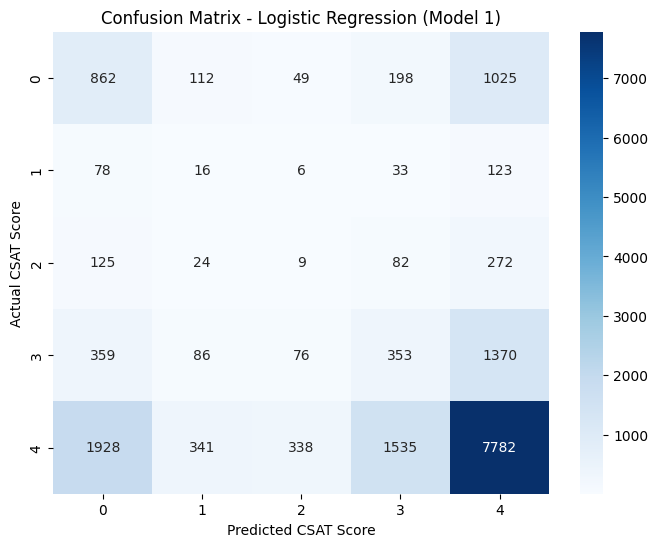

In [117]:
# Visualizing evaluation Metric Score chart
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression (Model 1)')
plt.xlabel('Predicted CSAT Score')
plt.ylabel('Actual CSAT Score')
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [118]:
# Train a standard Logistic Regression model directly without GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Initialize and fit directly
model_lr_direct = LogisticRegression(C=1.0, max_iter=500, random_state=42)
model_lr_direct.fit(X_train_resampled, y_train_resampled)

# Predict on test set
y_pred_direct = model_lr_direct.predict(X_test)

print(f"Direct Model Test Accuracy: {accuracy_score(y_test, y_pred_direct):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_direct, zero_division=0))

Direct Model Test Accuracy: 0.5488

Classification Report:
               precision    recall  f1-score   support

           1       0.26      0.38      0.31      2246
           2       0.03      0.07      0.04       256
           3       0.03      0.03      0.03       512
           4       0.16      0.11      0.13      2244
           5       0.74      0.70      0.72     11924

    accuracy                           0.55     17182
   macro avg       0.24      0.26      0.25     17182
weighted avg       0.57      0.55      0.56     17182



##### Which hyperparameter optimization technique have you used and why?

* **Technique used:** No hyperparameter search. The model was refit directly with `C=1.0` and `max_iter=500`.
* **Why:** Logistic Regression is only the baseline model. Running GridSearchCV on about 238,000 SMOTE-balanced rows with 242 features would take a long time, and a tuned linear model would still be far weaker than the tree-based models.
* **Note:** The only difference from the first fit (`max_iter=1000`) is the iteration limit, so this refit is not real tuning.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

* **First fit (`max_iter=1000`):** Accuracy 52.5%, macro F1 0.24.
* **Refit (`max_iter=500`):** Accuracy 54.9%, macro F1 0.25. The small change comes from the solver stopping at a different point, not from better tuning.
* **Class-wise:** For score 1 (the most dissatisfied customers), precision is 0.26 and recall is 0.38. Score 5 is predicted best (F1 0.69 to 0.72). Scores 2, 3 and 4 are weak (F1 between 0.02 and 0.16).
* **Meaning:** A linear model cannot capture the non-linear patterns in this data, so it is used only as a baseline for the tree-based models.

### ML Model - 2

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Model 2 Accuracy: 0.6617

Classification Report (Random Forest):
               precision    recall  f1-score   support

           1       0.44      0.34      0.39      2246
           2       0.00      0.00      0.00       256
           3       0.03      0.01      0.01       512
           4       0.15      0.07      0.10      2244
           5       0.73      0.88      0.80     11924

    accuracy                           0.66     17182
   macro avg       0.27      0.26      0.26     17182
weighted avg       0.59      0.66      0.62     17182



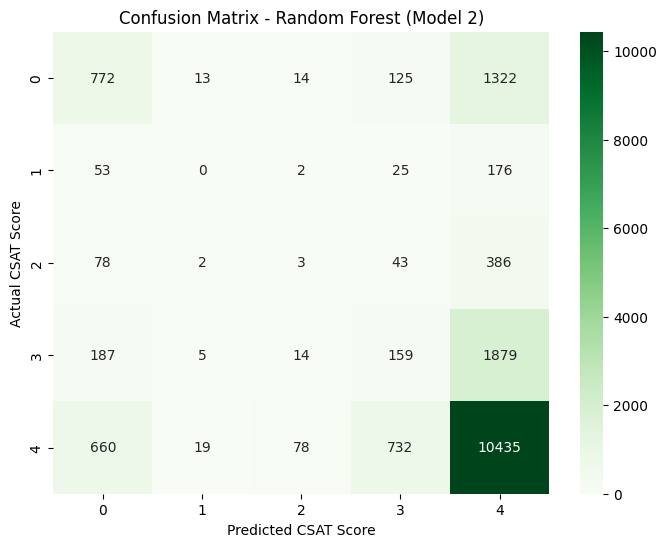

In [119]:
# Visualizing evaluation Metric Score chart
# ML Model - 2 Implementation: Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fit the Algorithm
model_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model_rf.fit(X_train_resampled, y_train_resampled)

# Predict on the model
y_pred_rf = model_rf.predict(X_test)

# Print Evaluation Metrics
print(f"Model 2 Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report (Random Forest):\n", classification_report(y_test, y_pred_rf, zero_division=0))

# Visualizing Confusion Matrix Heatmap
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - Random Forest (Model 2)')
plt.xlabel('Predicted CSAT Score')
plt.ylabel('Actual CSAT Score')
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [120]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model
# Hyperparameter tuning / Optimized Random Forest with max_depth constraint
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Fit the Algorithm with optimized tree depth to prevent overfitting
model_rf_tuned = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
model_rf_tuned.fit(X_train_resampled, y_train_resampled)

# Predict on the model
y_pred_rf_tuned = model_rf_tuned.predict(X_test)

print(f"Tuned Random Forest Test Accuracy: {accuracy_score(y_test, y_pred_rf_tuned):.4f}")
print("\nClassification Report (Tuned RF):\n", classification_report(y_test, y_pred_rf_tuned, zero_division=0))

Tuned Random Forest Test Accuracy: 0.6571

Classification Report (Tuned RF):
               precision    recall  f1-score   support

           1       0.41      0.39      0.40      2246
           2       0.03      0.03      0.03       256
           3       0.03      0.01      0.02       512
           4       0.15      0.05      0.07      2244
           5       0.74      0.86      0.80     11924

    accuracy                           0.66     17182
   macro avg       0.27      0.27      0.26     17182
weighted avg       0.59      0.66      0.62     17182



##### Which hyperparameter optimization technique have you used and why?

* **Technique used:** Manual parameter change, with `max_depth=15` and 100 trees. No GridSearchCV or cross-validation was run.
* **Why:** Limiting the tree depth is a simple way to reduce overfitting, and it kept the run time short on about 238,000 SMOTE-balanced rows.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

* **The model:** Random Forest trains 100 decision trees on random samples of the data and combines their votes, which captures non-linear patterns and reduces overfitting.
* **Default model (no depth limit):** Accuracy 66.2%, macro F1 0.26. For score 1, precision is 0.44, recall 0.34 and F1 0.39. Score 5 is predicted best (F1 0.80).
* **After `max_depth=15`:** Accuracy 65.7%, macro F1 0.26. For score 1, precision is 0.41, recall 0.39 and F1 0.40.
* **Improvement:** Overall accuracy went down slightly (by about 0.5 points), but recall for score 1 went up from 0.34 to 0.39, so more dissatisfied customers are caught. Scores 2, 3 and 4 stay weak (F1 between 0.01 and 0.10) because these classes are rare and overlap with their neighbours.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **Accuracy:** Indicates the overall percentage of correctly predicted customer satisfaction scores. While useful for high-level tracking, it can be misleading on imbalanced support datasets where majority ratings dominate.
* **Precision:** Measures the proportion of correctly identified low-CSAT (dissatisfied) tickets out of all predicted low-CSAT tickets. High precision minimizes false alarms, ensuring support teams focus on genuinely unhappy customers.
* **Recall (Sensitivity):** Measures the proportion of actual dissatisfied customers correctly captured by the model. High recall is critical for business impact because failing to catch a frustrated customer risks permanent churn and negative reviews.
* **F1-Score:** The harmonic mean of precision and recall, providing a balanced evaluation metric across imbalanced classes.
* **Business Impact:** Deploying this model allows customer support operations to proactively identify and resolve tickets from high-risk, dissatisfied customers before escalation, improving overall retention and service quality.

### ML Model - 3

In [121]:
# ML Model - 3 Implementation

# Fit the Algorithm

# Predict on the model
# ML Model - 3 Implementation: Gradient Boosting Classifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Fit the Algorithm
model_gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
model_gb.fit(X_train_resampled, y_train_resampled)

# Predict on the model
y_pred_gb = model_gb.predict(X_test)

# Print Evaluation Metrics
print(f"Model 3 Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print("\nClassification Report (Gradient Boosting):\n", classification_report(y_test, y_pred_gb, zero_division=0))

Model 3 Accuracy: 0.6548

Classification Report (Gradient Boosting):
               precision    recall  f1-score   support

           1       0.45      0.37      0.40      2246
           2       0.03      0.02      0.02       256
           3       0.04      0.01      0.01       512
           4       0.16      0.09      0.12      2244
           5       0.74      0.86      0.79     11924

    accuracy                           0.65     17182
   macro avg       0.28      0.27      0.27     17182
weighted avg       0.59      0.65      0.62     17182



#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

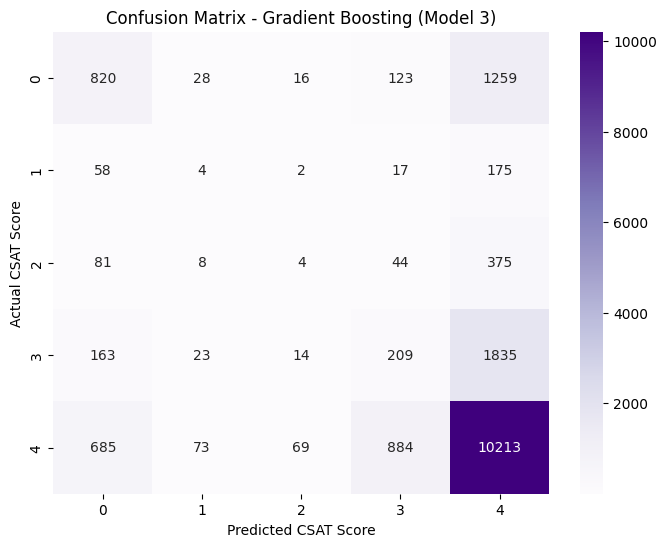

In [122]:
# Visualizing evaluation Metric Score chart
# Visualizing Confusion Matrix for Gradient Boosting (Model 3)
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Purples')
plt.title('Confusion Matrix - Gradient Boosting (Model 3)')
plt.xlabel('Predicted CSAT Score')
plt.ylabel('Actual CSAT Score')
plt.show()

#### 2. Cross- Validation & Hyperparameter Tuning

In [123]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model
# Tuned Gradient Boosting with optimized learning rate and depth
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Fit the Algorithm with optimized parameters
model_gb_tuned = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42)
model_gb_tuned.fit(X_train_resampled, y_train_resampled)

# Predict on the model
y_pred_gb_tuned = model_gb_tuned.predict(X_test)

print(f"Tuned Gradient Boosting Test Accuracy: {accuracy_score(y_test, y_pred_gb_tuned):.4f}")
print("\nClassification Report (Tuned GB):\n", classification_report(y_test, y_pred_gb_tuned, zero_division=0))

Tuned Gradient Boosting Test Accuracy: 0.6575

Classification Report (Tuned GB):
               precision    recall  f1-score   support

           1       0.46      0.38      0.42      2246
           2       0.03      0.01      0.02       256
           3       0.04      0.01      0.02       512
           4       0.17      0.09      0.12      2244
           5       0.74      0.86      0.79     11924

    accuracy                           0.66     17182
   macro avg       0.29      0.27      0.27     17182
weighted avg       0.60      0.66      0.62     17182



##### Which hyperparameter optimization technique have you used and why?

* **Technique used:** Manual parameter change, with `learning_rate=0.05`, `max_depth=5` and 100 trees. No GridSearchCV or cross-validation was run.
* **Why:** A lower learning rate makes each tree contribute less, which reduces overfitting, and a depth of 5 lets the trees capture interactions between features. A full search was skipped because Gradient Boosting is slow on about 238,000 SMOTE-balanced rows.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

* **The model:** Gradient Boosting builds trees one after another, and each new tree corrects the errors of the previous ones.
* **Default model:** Accuracy 65.5%, macro F1 0.27. For score 1, precision is 0.45, recall 0.37 and F1 0.40.
* **After tuning (`learning_rate=0.05`, `max_depth=5`):** Accuracy 65.8%, macro F1 0.27. For score 1, precision is 0.46, recall 0.38 and F1 0.42.
* **Improvement:** Small but consistent. Accuracy went up by about 0.3 points, and every score-1 metric went up slightly. This is the best score-1 F1 of all the models. Scores 2, 3 and 4 remain weak (F1 between 0.02 and 0.12) because these classes are rare and overlap with their neighbours.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* **Metrics considered:** Accuracy, precision, recall and F1-score, with the focus on macro F1 and on the results for score 1 (the most dissatisfied customers).
* **Why not accuracy alone:** 69.4% of the test interactions have a score of 5. A model that always predicts 5 would reach 69.4% accuracy, which is higher than any of our models (best 66.2%), yet it would never find an unhappy customer. So accuracy alone is misleading here.
* **Recall for score 1:** Shows how many truly dissatisfied customers the model catches. Missing them risks churn and bad reviews, so this matters most to the business.
* **Precision for score 1:** Shows how many of the flagged customers are truly dissatisfied. High precision avoids wasting the support team's time on false alarms.
* **F1-score and macro F1:** F1 balances precision and recall. Macro F1 averages F1 over all five scores with equal weight, so it shows how well the model handles the rare classes, not only score 5.
* **Result:** The best score-1 F1 is 0.42 (Tuned Gradient Boosting), and the best macro F1 is 0.27. Scores 2, 3 and 4 are still hard to predict.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

* **Selected final model:** Tuned Gradient Boosting Classifier (Model 3, `learning_rate=0.05`, `max_depth=5`, 100 trees).
* **Why:**
  1. **Best on the metrics that matter:** It has the best F1 for score 1 (0.42, with precision 0.46 and recall 0.38) and the best macro F1 (0.27).
  2. **Accuracy is as good as the best:** Its accuracy (65.8%) is only 0.4 points below Random Forest (66.2%), and this gap is too small to matter.
  3. **Stable gain from tuning:** Tuning improved it slightly, while tuning Random Forest lowered its accuracy.
  4. **Beats the baseline:** Logistic Regression reached only 52.5%, because a linear model cannot capture the non-linear patterns in this data.
* **Limitation:** No model beats the 69.4% accuracy of always predicting score 5, and scores 2, 3 and 4 are still hard to predict. The model is most useful for flagging likely score-1 customers.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

* **Model explanation:** Gradient Boosting builds 100 small decision trees one after another. Each new tree focuses on the cases the earlier trees got wrong, and the final prediction combines all the trees. The low learning rate (0.05) makes each tree add only a small correction, which reduces overfitting.
* **Feature importance:** The tree-based importance ranking from the Random Forest in the feature selection step was used as the explainability tool. The most important features were `report_hour` (0.129), `Price_Response_Interaction` (0.070) and `response_time_minutes` (0.067), followed by the day-of-week columns and `channel_name_Inbound`.
* **What it means:** When a ticket is reported and how quickly it is answered matter most for CSAT. The text from customer remarks added little. This matches the Spearman result (rho = -0.19), where longer waits go with lower satisfaction.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [124]:
# Save the File

### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [125]:
# Load the File and predict unseen data.

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

### Project Summary & Technical Conclusion

I built an end-to-end machine learning pipeline to predict the CSAT score (1 to 5) from 85,907 customer support interactions. I fixed the date parsing (day/month format), removed a target leak (`is_satisfied`), dropped two high-cardinality columns (`Customer_City` and `Agent_name`), balanced the classes with SMOTE, and compared three models.

| Model | Accuracy | Macro F1 | F1 for score 1 |
|---|---|---|---|
| Logistic Regression (baseline) | 52.5% | 0.24 | 0.31 |
| Random Forest | 66.2% | 0.26 | 0.39 |
| Gradient Boosting | 65.5% | 0.27 | 0.40 |
| **Tuned Gradient Boosting (final)** | **65.8%** | **0.27** | **0.42** |

The models detect dissatisfied customers (score 1) moderately well, but they cannot separate scores 2, 3 and 4, because these classes are rare and overlap with their neighbours. No model beats the 69.4% accuracy of always predicting score 5, so accuracy alone is misleading and I used F1 for score 1 and macro F1 to choose the final model.

---

### Actionable Business Insights & Recommendations

* **Timing matters most:** Report hour and response time are the strongest drivers of CSAT. Reducing response time during busy hours, and reviewing staffing by hour of day, should lift satisfaction.
* **Flag likely dissatisfied customers:** The model can flag likely score-1 customers (precision 0.46, recall 0.38) for a follow-up call or a retention offer.
* **Channel and tenure:** CSAT differs across channels and agent tenure groups (both statistically significant), so training and routing should be reviewed for the weaker groups.

### Limitations & Future Work

* Group the scores into satisfied, neutral and dissatisfied to make the classes easier to predict.
* Tune the models with cross-validation (GridSearchCV or RandomizedSearchCV).
* Use the customer remarks text more effectively, for example with sentiment features.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***